<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-14/lab-078-hopfield.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 078. The Hopfield network as an associative memory

A computer memory returns the content stored at a given address. An associative memory is addressed by its content, since it receives a corrupted or incomplete version of a stored pattern, called the cue, and returns the stored pattern closest to the cue. Hopfield showed that a network of interacting spins performs this task [1]. Every configuration of the spins has an energy, the couplings between the spins are chosen so that each stored pattern lies at a minimum of this energy, and the spins are updated one at a time so that the energy decreases. Started from the cue, the network relaxes to a nearby minimum, and for a cue close enough to a stored pattern this minimum is the pattern.

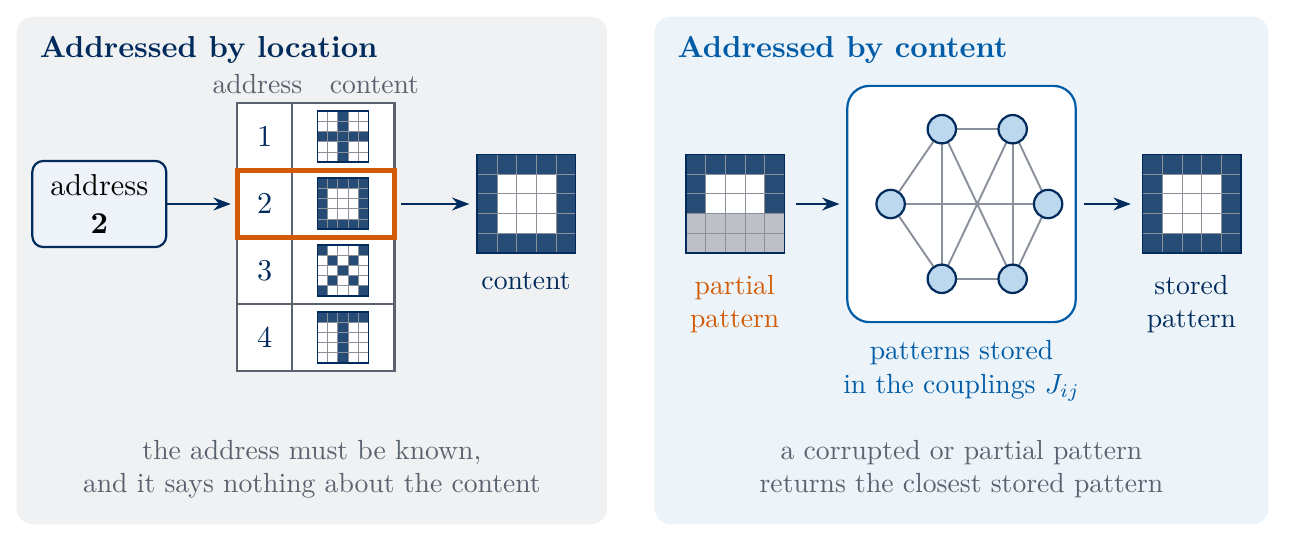

The sketch compares the two kinds of memory. On the left an address selects one entry of a table, and the address carries no information on the content. On the right a partial pattern is given to a network of coupled spins, whose couplings $J_{ij}$ hold the stored patterns, and the network returns the complete pattern.

We are given $p$ patterns, each a configuration of $N$ spins. We choose the couplings between the spins from the patterns by a fixed rule, so nothing is trained iteratively. The cue is the initial configuration of the spins, and the configuration at which the dynamics stops is the output that we observe. The goal is a network that returns a stored pattern from a cue in which part of the spins is masked or flipped. We also measure how many patterns such a network holds and find the ways in which it fails.

Lab 078a built this network on digit images and portraits. It introduced the Hebbian rule, the energy, recall one spin at a time, the overlaps and the majority image of three digits, so these parts can be read quickly here, with the caution that the equation numbers differ. New in this notebook are random patterns, the cross-talk and its Gaussian statistics, the measured recall rate, the cascade of flips, the search for spurious minima and the dense memories. Lab 079 then continues with learned couplings and hidden units.

Sections 1 to 9 form the core route, which takes about one minute. We define the energy and the update rule, show that an update never raises the energy, and check this numerically at every flip. We store one pattern, and then several patterns with the Hebbian rule. The field that acts on a spin of a stored pattern splits into a signal and a cross-talk term from the other patterns, and we measure both. Written in terms of the overlaps with the stored patterns, the energy has a valley at every pattern, and we follow a recall through these overlaps. We restore images of handwritten digits from masked and from noisy cues, measure the recall rate against the load $p/N$ for random patterns, follow the cascade of flips that carries the network away from a stored pattern above the storage limit, and search for minima that were never stored. The core route ends with these spurious memories and a summary of Sections 2 to 9. Section 10 is work at home and takes about one minute more. It treats a dense associative memory with a quartic energy and one update of a network with Boltzmann weights. Section 11 summarises that part and Section 12 contains exercises.

All results come from simulations with fixed random seeds. Recalls of single images are single runs and are labelled as such, whereas the recall rates are averages over many sets of random patterns and carry standard errors. The storage limit $p\approx0.138N$ comes from Ref. [2], and we compare our finite networks with it without deriving it. The digit images are derived from the MNIST training set of handwritten digits [3]. A pixel of a training image counts as ink when its grey value exceeds half of the maximum, and a pixel of the image of a digit is ink when it is ink in more than half of the training images of that digit. These ten binary images of $28\times28$ pixels are supplied in a small data file together with the notebook, so no download is needed.

## 1. Libraries

NumPy performs all computations in double precision on the CPU, and Matplotlib draws the figures. The cells run in order. All random numbers of the core route come from one generator, so a cell that is run twice changes every later number. To return to the numbers quoted in the text, restart the notebook and run all cells from the top. We write array shapes as `(p, N)`, meaning $p$ rows and $N$ columns. The drawing code is in the collapsed cell after the imports, and each figure is produced by one call to it. The other collapsed cells only count flips, measure run times or store the results in a file, and they can be skipped.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['lab078_mnist_class_means.npz']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-14/data/{name}", f"data/{name}")

In [1]:
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "4")                     # at most four CPU threads, set before NumPy is imported
import json, math, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DATA = Path("data")                                          # the file with the ten digit images is read from here

# One random generator with a fixed seed serves the core route. Every call such as rng.choice(...) advances its state.
rng = np.random.default_rng(78)
print("NumPy", np.__version__)

NumPy 2.1.3


In [2]:
# Figure code and bookkeeping. Figures go to figures_lab078 unless the course build sets L14_EXPORT=1.
EXPORT = os.environ.get("L14_EXPORT") == "1"
FIG = Path("figures" if EXPORT else "figures_lab078"); FIG.mkdir(exist_ok=True)
RES = Path("classroom_results")
started = time.perf_counter()
CHECKED = dict(runs=0, flips=0)
REPORT = {}
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.6, 3.1), "savefig.bbox": "tight",
                     "pdf.fonttype": 42, "ps.fonttype": 42})
# colour roles: recalled stored pattern and simulation blue, other stored patterns grey, reference curves orange,
# inverted patterns navy, spurious mixtures purple, further series navy, purple and teal
COL = dict(recall="#005CA7", other="#9AA0A6", ref="#D35A05", navy="#002B5C", purple="#6A3D9A", teal="#1B9E77")
LARGE_FONT = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12}

def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)

def panels(name, draws):
    # panels side by side at 7.0 x 2.9 in, and every panel also as its own file at 4.6 x 3.1 in with larger fonts
    fig, axes = plt.subplots(1, len(draws), figsize=(7.0, 2.9))
    for ax, draw, lab in zip(axes, draws, "abcdef"):
        draw(ax, f"({lab})")
    fig.tight_layout(); save(fig, name); plt.show()
    for draw, lab in zip(draws, "abcdef"):
        with plt.rc_context(LARGE_FONT):
            single, ax = plt.subplots(figsize=(4.6, 3.1))
            draw(ax, None)
            single.tight_layout(); save(single, f"{name}_{lab}"); plt.close(single)

def tag(ax, lab, x=0.03, y=0.95):
    if lab:
        ax.text(x, y, lab, transform=ax.transAxes, va="top", ha="left")

def show_image(ax, s, title=None):
    ax.imshow(s.reshape(28, 28), cmap="gray", vmin=-1, vmax=1)      # spin +1 white, spin -1 black
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_color(COL["other"])
    if title:
        ax.set_title(title)

def plot_energy_descent(glass_runs):
    fig, ax = plt.subplots()
    for E, c in zip(glass_runs, (COL["navy"], COL["recall"], COL["teal"], COL["purple"], COL["other"])):
        ax.plot(E, color=c, lw=1.6)
    ax.set_xlabel("number of flips"); ax.set_ylabel("energy per spin $E/N$")
    fig.tight_layout(); save(fig, "fig_lab078_energy_descent"); plt.show()

def plot_one_pattern(xi_one, frames):
    fig, axes = plt.subplots(1, 5, figsize=(7.0, 1.9))
    show_image(axes[0], xi_one, "stored")
    for k, (cue, s_end, m_cue, m_end) in enumerate(frames):
        show_image(axes[1 + 2 * k], cue, f"cue, $m={m_cue:+.1f}$")
        show_image(axes[2 + 2 * k], s_end, f"result, $m={m_end:+.0f}$")
    fig.tight_layout(); save(fig, "fig_lab078_one_pattern"); plt.show()

def plot_crosstalk(C_hist, crosstalk, loads):
    def draw_hist(ax, lab):
        x = np.linspace(-1.9, 1.9, 300)
        ax.hist(C_hist, bins=np.linspace(-1.9, 1.9, 77), density=True, color=COL["recall"], alpha=0.75, label="measured")
        ax.plot(x, np.exp(-x ** 2 / 0.4) / np.sqrt(0.4 * np.pi), color=COL["ref"], lw=2, label="Gaussian")
        ax.axvline(-1, color="black", ls="--", lw=1.2)
        ax.text(-1.06, 0.55, "flip", rotation=90, ha="right", va="center")
        ax.set_xlabel(r"cross-talk $C_i^\nu$"); ax.set_ylabel("density"); ax.set_ylim(0, 1.3)
        ax.legend(frameon=False, loc="upper right", handlelength=1.2); tag(ax, lab)
    def draw_tail(ax, lab):
        a_grid = np.linspace(0.06, 0.52, 200)
        ax.semilogy(a_grid, [tail(a) for a in a_grid], color=COL["ref"], lw=2, label="Gaussian tail")
        ax.errorbar(loads, [crosstalk[a]["fraction"] for a in loads], yerr=[crosstalk[a]["error"] for a in loads],
                    fmt="o", color=COL["recall"], capsize=3, label="measured")
        ax.set_xlabel(r"load $\alpha=p/N$"); ax.set_ylabel("fraction of misaligned spins")
        ax.legend(frameon=False, loc="lower right"); tag(ax, lab)
    panels("fig_lab078_crosstalk", [draw_hist, draw_tail])

def plot_overlaps(m_run, E_run, E_from_m, E_pattern):
    def draw_m(ax, lab):
        ax.plot(m_run[:, 1:], color=COL["other"], lw=0.8)
        ax.plot([], [], color=COL["other"], lw=0.8, label=f"other {m_run.shape[1] - 1} patterns")
        ax.plot(m_run[:, 0], color=COL["recall"], lw=2.2, label="cued pattern")
        ax.set_xlabel("number of flips"); ax.set_ylabel(r"overlap $m_\mu$"); ax.set_ylim(-0.25, 1.08)
        ax.legend(frameon=False, loc="center right"); tag(ax, lab)
    def draw_E(ax, lab):
        ax.plot(E_run, color=COL["recall"], lw=2.2, label="sum over spin pairs")
        ax.plot(E_from_m, color=COL["ref"], lw=1.4, ls="--", label="from the overlaps")
        ax.axhline(E_pattern, color="black", lw=1, ls=":", label="stored pattern")
        ax.set_xlabel("number of flips"); ax.set_ylabel("energy $E$")
        ax.legend(frameon=False, loc="lower left"); tag(ax, lab, x=0.88, y=0.95)
    panels("fig_lab078_overlaps", [draw_m, draw_E])

def plot_digit_recall(rows):
    # rows: one (cue, flips, stored digit) per row of the figure
    fig, axes = plt.subplots(2, 5, figsize=(7.0, 3.4))
    for row, (cue, flips, stored) in enumerate(rows):
        stops = [0, len(flips) // 3, 2 * len(flips) // 3, len(flips)]
        for col, stop in enumerate(stops):
            s = cue.copy()
            for i in flips[:stop]:
                s[i] = -s[i]                                         # configuration after the first `stop` flips
            show_image(axes[row, col], s, "cue" if col == 0 else ("fixed point" if col == 3 else f"{stop} flips"))
        show_image(axes[row, 4], stored, "stored")
    fig.tight_layout(); save(fig, "fig_lab078_digit_recall"); plt.show()

def plot_digit_blend(xi_triple, labels, s_end):
    fig, axes = plt.subplots(1, 4, figsize=(7.0, 2.1))
    for k in range(3):
        show_image(axes[k], xi_triple[k], f"stored {labels[k]}")
    show_image(axes[3], s_end, "fixed point")
    fig.tight_layout(); save(fig, "fig_lab078_digit_blend"); plt.show()

def plot_capacity(capacity, loads, sizes, alpha_c):
    style = {250: (COL["teal"], "s"), 500: (COL["purple"], "^"), 1000: (COL["navy"], "o")}
    def mark_limit(ax):
        ax.axvline(alpha_c, color=COL["ref"], ls="--", lw=1.6)
        ax.text(alpha_c - 0.004, 0.5, rf"$\alpha_c={alpha_c}$", color=COL["ref"], ha="right", transform=ax.get_xaxis_transform())
    def draw_rate(ax, lab):
        for N in sizes:
            c, mk = style[N]
            ax.errorbar(loads, capacity[N]["rate"], yerr=capacity[N]["rate_err"], fmt=mk + "-", color=c, ms=4, lw=1.2, capsize=2, label=f"$N={N}$")
        mark_limit(ax)
        ax.set_xlabel(r"load $\alpha=p/N$"); ax.set_ylabel("recall rate"); ax.set_ylim(-0.04, 1.06)
        ax.legend(frameon=False, loc="lower left", handlelength=1.4); tag(ax, lab, x=0.86, y=0.95)
    def draw_overlap(ax, lab):
        for N in sizes:
            c, mk = style[N]
            ax.errorbar(loads, capacity[N]["m"], yerr=capacity[N]["m_err"], fmt=mk + "-", color=c, ms=4, lw=1.2, capsize=2, label=f"$N={N}$")
        mark_limit(ax)
        ax.set_xlabel(r"load $\alpha=p/N$"); ax.set_ylabel("mean final overlap"); ax.set_ylim(0, 1.06)
        tag(ax, lab, x=0.86, y=0.95)
    panels("fig_lab078_capacity", [draw_rate, draw_overlap])

def plot_cascade(cascade, traces, shown):
    colours = dict(zip(shown, (COL["teal"], COL["purple"], COL["navy"])))
    loads = sorted(cascade)
    def draw_traces(ax, lab):
        for a in reversed(shown):                                    # the longest runs first, the short ones on top
            for trace in traces[a]:
                ax.plot(trace, color=colours[a], lw=0.9, alpha=0.6)
                ax.plot(len(trace) - 1, trace[-1], "o", color=colours[a], ms=3.5)   # the point at which this run stops
        for a in shown:
            ax.plot([], [], color=colours[a], lw=1.8, label=rf"$\alpha={a:.3g}$")
        ax.set_xscale("symlog", linthresh=10); ax.set_xlim(0, 1000)
        ax.set_xlabel("number of flips"); ax.set_ylabel("overlap with the pattern"); ax.set_ylim(0, 1.05)
        ax.legend(frameon=False, loc="lower left"); tag(ax, lab, x=0.88, y=0.95)
    def draw_counts(ax, lab):
        ax.plot(loads, [cascade[a]["misaligned_at_start"] for a in loads], "o--", color=COL["ref"], ms=4, lw=1.4, label="misaligned at the start")
        ax.plot(loads, [cascade[a]["flips"] for a in loads], "s-", color=COL["recall"], ms=4, lw=1.6, label="flips until the fixed point")
        ax.set_yscale("symlog", linthresh=1); ax.set_ylim(0, 30000)
        ax.set_xlabel(r"load $\alpha=p/N$"); ax.set_ylabel("spins (mean per run)")
        ax.legend(frameon=False, loc="upper left"); tag(ax, lab, x=0.90, y=0.13)
    panels("fig_lab078_cascade", [draw_traces, draw_counts])

def plot_spurious(classes, fractions, frac_err, found):
    colours = {"stored pattern": COL["recall"], "inverted pattern": COL["navy"], "mixture of three": COL["purple"], "other": COL["other"]}
    short = {"stored pattern": "stored", "inverted pattern": "inverted", "mixture of three": "mixture", "other": "other"}
    def draw_fraction(ax, lab):
        ax.bar(range(4), [fractions[c] for c in classes], yerr=[frac_err[c] for c in classes], color=[colours[c] for c in classes], capsize=3)
        ax.set_xticks(range(4)); ax.set_xticklabels([short[c] for c in classes], rotation=20)
        ax.set_ylabel("fraction of random starts"); ax.set_ylim(0, 0.5); ax.set_xlim(-0.6, 3.6); tag(ax, lab)
    def draw_energy(ax, lab):
        jitter = np.random.default_rng(0)                            # horizontal scatter of the points, separate from `rng`
        for x, c in enumerate(classes):
            e = np.array(found[c])
            ax.plot(x + 0.5 * (jitter.random(len(e)) - 0.5), e, ".", color=colours[c], ms=3, alpha=0.6)
        ax.axhline(-0.5, color=COL["ref"], ls="--", lw=1.4); ax.axhline(-0.375, color=COL["ref"], ls=":", lw=1.8)
        ax.text(3.55, -0.497, "$-1/2$", color=COL["ref"], va="bottom", ha="right"); ax.text(3.55, -0.372, "$-3/8$", color=COL["ref"], va="bottom", ha="right")
        ax.set_xticks(range(4)); ax.set_xticklabels([short[c] for c in classes], rotation=20)
        ax.set_ylabel("energy per spin $E/N$"); ax.set_ylim(-0.54, -0.30); ax.set_xlim(-0.6, 3.6); tag(ax, lab)
    panels("fig_lab078_spurious", [draw_fraction, draw_energy])

def plot_dense(dense):
    fig, ax = plt.subplots()
    for n, c, mk in ((2, COL["recall"], "o"), (4, COL["teal"], "s")):
        ax.errorbar(dense[n]["p"], dense[n]["rate"], yerr=dense[n]["err"], fmt=mk + "-", color=c, ms=4, lw=1.2, capsize=2, label=f"$n={n}$")
    ax.set_xscale("log"); ax.set_xlabel("number of stored patterns $p$"); ax.set_ylabel("recall rate"); ax.set_ylim(-0.04, 1.06)
    ax.legend(frameon=False, loc="lower left")
    fig.tight_layout(); save(fig, "fig_lab078_dense_capacity"); plt.show()

def plot_boltzmann(masked_cues, outputs):
    fig, axes = plt.subplots(2, 10, figsize=(7.0, 1.75))
    for d in range(10):
        show_image(axes[0, d], masked_cues[d]); show_image(axes[1, d], outputs[d])
    axes[0, 0].set_ylabel("cue"); axes[1, 0].set_ylabel("output")
    fig.tight_layout(pad=0.3); save(fig, "fig_lab078_boltzmann_update"); plt.show()

## 2. Spins, energy and asynchronous dynamics

The network consists of $N$ spins $s_i=\pm1$ with $i=1,\dots,N$, and a configuration is the vector $\mathbf s=(s_1,\dots,s_N)$. Every pair of spins interacts through a coupling $J_{ij}$. The couplings are symmetric, $J_{ij}=J_{ji}$, and no spin couples to itself, $J_{ii}=0$. The energy of a configuration is
$$E(\mathbf s)=-\frac12\sum_{i,j=1}^{N}J_{ij}\,s_is_j . \tag{1}$$
A positive coupling lowers the energy when the two spins are equal, and a negative coupling lowers it when they are opposite. This is the energy of an Ising model in which every pair of spins has its own coupling. The double sum contains every pair twice, which the factor $\tfrac12$ compensates.

All other spins act on spin $i$ through its local field
$$\phi_i=\sum_{j=1}^{N}J_{ij}\,s_j . \tag{2}$$
The dynamics aligns one spin at a time with its field,
$$s_i\leftarrow\mathrm{sign}(\phi_i) , \tag{3}$$
and a spin with $\phi_i=0$ keeps its value. Later models add to the field of each unit a constant of its own, called a bias, and this network has none, so the local field contains the couplings only. Dynamics that updates a single spin per move is called asynchronous.

To show that such an update never raises the energy, we collect the terms of equation (1) that contain a chosen spin $s_k$. They are the terms with $i=k$ and the terms with $j=k$, and by the symmetry of the couplings the two groups are equal, so
$$E(\mathbf s)=-s_k\sum_{j}J_{kj}\,s_j+\big(\text{terms without }s_k\big)=-s_k\phi_k+\big(\text{terms without }s_k\big) .$$
The field $\phi_k$ does not contain $s_k$, because $J_{kk}=0$. A flip $s_k\to-s_k$ therefore changes the energy by
$$\Delta E=2s_k\phi_k , \tag{4}$$
where $s_k$ is the value before the flip. The rule (3) flips the spin only if it points against its field, $s_k\phi_k<0$, and then $\Delta E=-2|\phi_k|<0$. The network has $2^N$ configurations, and a strictly decreasing energy visits no configuration twice, so the dynamics stops after a finite number of flips. In the final configuration every spin is aligned with its field or has zero field, and no single flip lowers the energy further. Such a configuration is a fixed point of the dynamics and a local minimum of the energy.

The proof relies on the symmetry of the couplings, on the update of one spin per move and on the zero diagonal, and Exercise 1 examines what happens without each of them. Keeping a spin at $\phi_k=0$ makes every flip a strict decrease. A flip at zero field would leave the energy unchanged, and a rule that flipped such a spin could move between configurations of equal energy without end.

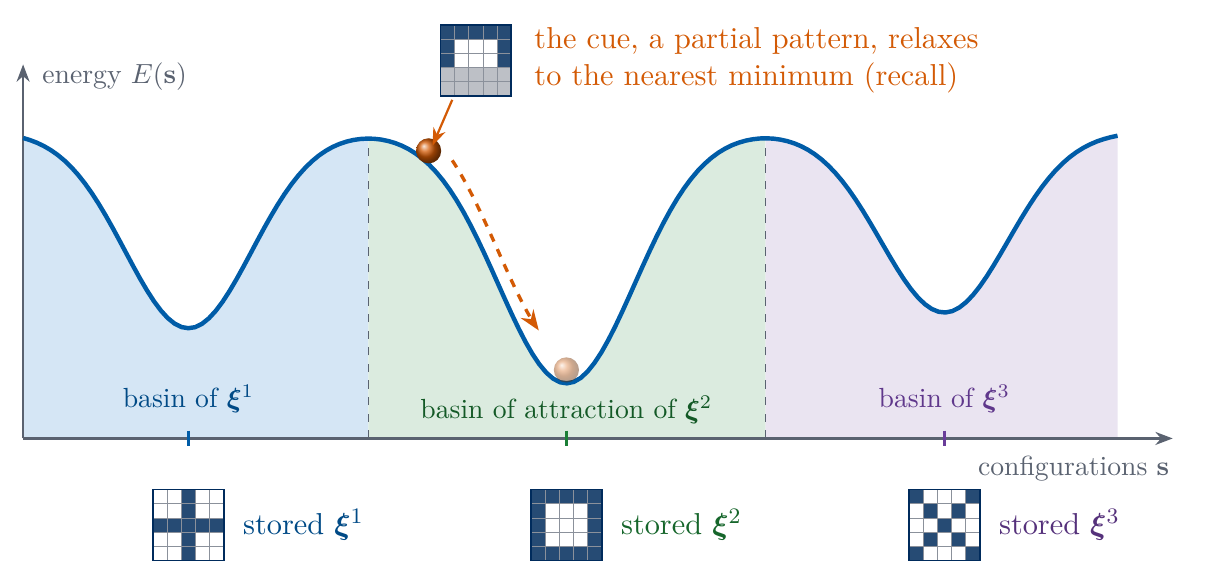

The sketch draws the energy as a landscape over the configurations, with one valley for each of three stored patterns. The set of configurations from which the dynamics reaches a given minimum is called the basin of attraction of that minimum, and a cue inside the basin of a pattern relaxes to that pattern.

The next cell turns equations (1) to (3) into code. The function `energy` takes the coupling matrix `J` of shape `(N, N)` and a configuration `s` of shape `(N,)` and returns the number $E(\mathbf s)$. The function `relax` takes the same two arrays and a random generator and returns the configuration at which the dynamics stops, and on request also the list of spins that flipped. In each pass it visits only the spins that point against their field, in random order, because rule (3) leaves every other spin unchanged, and it tests each of them again before the flip, since earlier flips of the pass change the fields. It keeps the local fields $\phi_i$ in the array `phi` of shape `(N,)`. Computing them anew after every flip would cost $N^2$ operations, whereas a flip of spin $i$ changes the field of every spin $j$ by $2J_{ji}s_i$, with the new value of $s_i$, and adding this change costs $N$ operations.

In [3]:
TOL = 1e-9     # fields smaller than this count as zero, so a spin with phi_i = 0 keeps its value despite rounding errors

def energy(J, s):
    # Equation (1). The operator @ is the matrix product and is evaluated from left to right here,
    # (-0.5 s) @ J gives a vector of shape (N,), and its product with s gives the number -1/2 sum_ij s_i J_ij s_j.
    return -0.5 * s @ J @ s

def relax(J, s, rng, record=False):
    # Asynchronous dynamics (3): flip one misaligned spin at a time until every spin is aligned with its field.
    s = s.copy()                                         # work on a copy, so that the cue of the caller stays unchanged
    phi = J @ s                                          # local fields phi_i of equation (2), shape (N,)
    flips = []
    while True:
        # s * phi multiplies entry by entry, and s_i phi_i < 0 means that spin i points against its field.
        # np.flatnonzero returns the indices at which the condition holds.
        misaligned = np.flatnonzero(s * phi < -TOL)
        if misaligned.size == 0:
            break                                        # no misaligned spin is left, so this is a fixed point
        for i in rng.permutation(misaligned):            # visit these spins in random order
            if s[i] * phi[i] < -TOL:                     # earlier flips of this pass may have changed the field of spin i
                s[i] = -s[i]
                # J[i] is row i of J, shape (N,). J is symmetric, so the row equals the column J_ji needed here.
                phi += 2 * s[i] * J[i]                   # phi_j changes by 2 J_ji s_i, with the new s_i
                flips.append(i)
    return (s, np.array(flips, dtype=int)) if record else s

The function `replay` serves as an independent check. It takes an initial configuration and the recorded list of flips, repeats the flips, and recomputes the energy from equation (1) after each of them, so it does not rely on equation (4). It stops with an error if any flip fails to lower the energy. When the patterns `xi`, of shape `(p, N)`, are passed, it also records all overlaps with them, which Section 6 uses.

In [4]:
def replay(J, s0, flips, xi=None):
    s = s0.copy()
    E = [energy(J, s)]                                   # energy after 0, 1, 2, ... flips
    m = [xi @ s / s.size] if xi is not None else None    # xi @ s has shape (p,), one overlap per pattern
    for i in flips:
        s[i] = -s[i]
        E.append(energy(J, s))
        if xi is not None:
            m.append(xi @ s / s.size)
    E = np.array(E)
    assert np.all(np.diff(E) < 0), "a flip raised the energy"   # np.diff gives E[t + 1] - E[t]
    return (E, np.array(m)) if xi is not None else E

In [5]:
# Bookkeeping, can be skipped. Wraps replay so that every call adds its runs and flips to CHECKED, which Section 9 prints.
_replay_without_count = replay
def replay(J, s0, flips, xi=None):
    CHECKED["runs"] += 1; CHECKED["flips"] += len(flips)
    return _replay_without_count(J, s0, flips, xi)

We test both functions on couplings that store nothing. For $N=200$ spins we draw a matrix of independent Gaussian numbers and symmetrise it, which gives couplings of zero mean and variance $1/N$, and we set the diagonal to zero. With this scale the sum of $N$ random terms in the field (2) stays of order one for every $N$, the same reason for which the Hebbian rule of Section 4 contains the factor $1/N$. We then start the dynamics from five random configurations. The list `glass_runs` receives one array per run with the energy per spin after every flip.

run 1:  89 flips, energy per spin -0.068 -> -0.604, smallest energy drop of a flip 2.4e-02
run 2:  98 flips, energy per spin -0.070 -> -0.644, smallest energy drop of a flip 4.1e-03
run 3: 109 flips, energy per spin -0.052 -> -0.672, smallest energy drop of a flip 1.3e-02
run 4: 126 flips, energy per spin +0.009 -> -0.687, smallest energy drop of a flip 8.1e-03
run 5: 105 flips, energy per spin +0.012 -> -0.613, smallest energy drop of a flip 6.1e-03
distinct final energies: 5 of 5


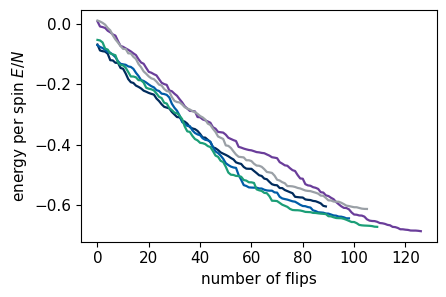

In [6]:
N_GLASS = 200
G = rng.normal(size=(N_GLASS, N_GLASS))                  # independent Gaussian numbers, shape (N, N)
J_glass = (G + G.T) / np.sqrt(2 * N_GLASS)               # G.T is the transpose, so J_ij = J_ji with variance 1/N
np.fill_diagonal(J_glass, 0.0)                           # sets J_ii = 0 inside the existing array

glass_runs = []
for run in range(5):
    s0 = rng.choice([-1.0, 1.0], size=N_GLASS)           # random configuration of +1 and -1, shape (N,)
    s_end, flips = relax(J_glass, s0, rng, record=True)
    E = replay(J_glass, s0, flips)                       # stops with an error if a flip did not lower the energy
    assert np.all(s_end * (J_glass @ s_end) >= 0)        # every spin of the final configuration is aligned with its field
    glass_runs.append(E / N_GLASS)
    print(f"run {run + 1}: {len(flips):3d} flips, energy per spin {E[0] / N_GLASS:+.3f} -> {E[-1] / N_GLASS:+.3f},"
          f" smallest energy drop of a flip {-np.diff(E).max():.1e}")
glass_final = np.array([E[-1] for E in glass_runs])
print(f"distinct final energies: {len(np.unique(np.round(glass_final, 6)))} of {len(glass_runs)}")
plot_energy_descent(glass_runs)

The figure shows the energy per spin against the number of flips for the five runs, one curve per initial configuration. The energy decreases at every flip of all five runs, which need between 89 and 126 flips, and the printed smallest drop is the flip that lowered the total energy $E$ least. The runs end in five different fixed points, with energies per spin between $-0.69$ and $-0.60$. Random couplings thus produce many minima at configurations that nobody chose. In the next sections we choose the couplings so that the minima lie at the patterns we want to store.

## 3. One stored pattern

A pattern is a fixed configuration $\boldsymbol\xi=(\xi_1,\dots,\xi_N)$ with $\xi_i=\pm1$ that the network should remember. For an image every pixel is one spin. A pixel is a bit $b_i\in\{0,1\}$ with $b_i=1$ for ink, and the relation $s_i=1-2b_i$ turns it into a spin, so $\xi_i=+1$ for a background pixel and $\xi_i=-1$ for an ink pixel. To make a single pattern a minimum we couple two spins positively when they are equal in the pattern and negatively when they differ,
$$J_{ij}=\frac1N\,\xi_i\xi_j\quad(i\neq j),\qquad J_{ii}=0 . \tag{5}$$
The field (2) then becomes
$$\phi_i=\frac{\xi_i}{N}\sum_{j\neq i}\xi_js_j=\xi_i\Big(m-\frac{\xi_is_i}{N}\Big),\qquad m=\frac1N\sum_{j=1}^N\xi_js_j . \tag{6}$$
The number $m$ is the overlap of the configuration with the pattern. It equals $1$ for $\mathbf s=\boldsymbol\xi$ and $-1$ for the inverted pattern $\mathbf s=-\boldsymbol\xi$, and it equals $1-2d/N$ when $d$ spins differ from the pattern. At the pattern itself the field is $\phi_i=\xi_i(N-1)/N$, which has the sign of $\xi_i$ for every spin, so the pattern is a fixed point. For any configuration with $|m|>1/N$ the field (6) has the sign of $\xi_i$ if $m>0$ and the sign of $-\xi_i$ if $m<0$. Every spin is therefore pulled towards the pattern when the cue agrees with it on more than half of the spins, and towards the inverted pattern otherwise. The inverted pattern is a second minimum, because the energy (1) does not change when all spins are flipped.

In the variables $\tau_i=\xi_is_i$ every term of the energy becomes $J_{ij}s_is_j=\tau_i\tau_j/N$, because $\xi_i^2=1$. These are the couplings of a ferromagnet in which all pairs of spins interact with the same strength $1/N$, and the two minima are its two magnetised states.

In terms of the field, equation (1) reads $E=-\tfrac12\sum_is_i\phi_i$, and equation (6) gives $s_i\phi_i=\xi_is_i\,m-1/N$. Summing over $i$ with $\sum_i\xi_is_i=Nm$ yields
$$E=-\frac N2\,m^2+\frac12 ,$$
so the two minima $m=\pm1$ have the energy $-N/2+1/2$.

We store the image of the digit 3, with $N=784$ pixels, and start the dynamics from two cues, the pattern with 30 per cent and with 60 per cent of its pixels flipped at random positions. Each recall is a single run.

The next cell loads the ten digit images and defines `flip_fraction`, which produces a noisy cue. The data file holds the bits of the images in an array of shape `(10, 28, 28)`, and `reshape` turns every image into one row of length $N=784$, so `xi_digits` has shape `(10, 784)`. Row `xi_digits[d]` is the pattern of the digit $d$.

In [7]:
digits = np.load(DATA / "lab078_mnist_class_means.npz")      # the file holds the majority images described in the introduction
# reshape(10, -1) keeps 10 rows and lets NumPy compute the row length, here 28 * 28 = 784.
xi_digits = 1.0 - 2.0 * digits["bits"].reshape(10, -1)       # s = 1 - 2b: background +1 (white), ink -1 (black)
N_IMG = xi_digits.shape[1]

def flip_fraction(x, fraction, rng):
    # copy of the configuration x with a given fraction of its spins flipped, at randomly chosen positions
    y = x.copy()
    number_of_flips = int(round(fraction * x.size))
    positions = rng.choice(x.size, number_of_flips, replace=False)   # distinct indices, because replace=False
    y[positions] *= -1                                       # indexing with an array changes all these entries at once
    return y

print("xi_digits has shape", xi_digits.shape)

xi_digits has shape (10, 784)


We now build the couplings (5) for the digit 3 and run the two recalls. The function `np.outer(x, x)` returns the matrix with the entries $x_ix_j$, of shape `(N, N)`. For each cue the cell prints the overlap with the pattern, the number of flips and the energy before and after the recall. The figure shows the stored image and, for each run, the cue and the configuration at which the dynamics stops.

30% of the spins flipped: overlap of the cue +0.401, 235 flips, final overlap +1.000, energy -62.4 -> -391.5 (formula -N m^2/2 + 1/2 at |m| = 1: -391.5); spins that differ between cue and fixed point: 235
60% of the spins flipped: overlap of the cue -0.199, 314 flips, final overlap -1.000, energy -15.0 -> -391.5 (formula -N m^2/2 + 1/2 at |m| = 1: -391.5); spins that differ between cue and fixed point: 314


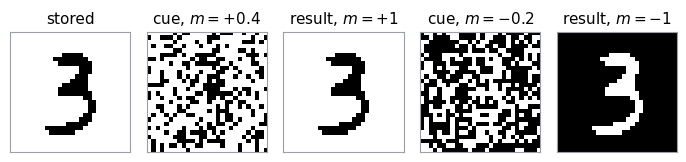

In [8]:
xi_one = xi_digits[3]                                        # the pattern, shape (N,)
J_one = np.outer(xi_one, xi_one) / N_IMG                     # J_ij = xi_i xi_j / N, equation (5)
np.fill_diagonal(J_one, 0.0)                                 # J_ii = 0
assert np.all(xi_one * (J_one @ xi_one) > 0)                 # xi_i phi_i > 0 for all i, so the pattern is a fixed point

one_pattern_runs = []
for fraction in (0.3, 0.6):
    cue = flip_fraction(xi_one, fraction, rng)
    s_end, flips = relax(J_one, cue, rng, record=True)
    # xi_one[None] adds a first axis, shape (1, N), because replay expects a table with one row per pattern.
    # It returns the energies E and the overlaps m with shape (flips + 1, 1).
    E, m = replay(J_one, cue, flips, xi_one[None])
    one_pattern_runs.append((cue, s_end, m[0, 0], m[-1, 0]))
    wrong_spins_in_cue = int(np.sum(cue != s_end))
    print(f"{fraction:.0%} of the spins flipped: overlap of the cue {m[0, 0]:+.3f}, {len(flips)} flips, final overlap {m[-1, 0]:+.3f},"
          f" energy {E[0]:.1f} -> {E[-1]:.1f} (formula -N m^2/2 + 1/2 at |m| = 1: {-N_IMG / 2 + 0.5:.1f});"
          f" spins that differ between cue and fixed point: {wrong_spins_in_cue}")
plot_one_pattern(xi_one, one_pattern_runs)

The first cue has the overlap $m=0.4$ with the stored digit and relaxes to it, $m=1$. The second cue has $m=-0.2$ and relaxes to the inverted digit, $m=-1$, as equation (6) predicts. In both runs the number of flips equals the number of spins that differ from the final configuration, 235 and 314, so every wrong spin flips once and no other spin moves. The final energy is $-N/2+1/2=-391.5$ in both cases.

## 4. Several patterns and the Hebbian rule

To store $p$ patterns $\boldsymbol\xi^\mu$ with $\mu=1,\dots,p$ we add the couplings (5) of all of them,
$$J_{ij}=\frac1N\sum_{\mu=1}^{p}\xi_i^\mu\xi_j^\mu\quad(i\neq j),\qquad J_{ii}=0 . \tag{7}$$
The coupling between two spins is positive when they are equal in most patterns and negative when they differ in most. The rule is called Hebbian, after the hypothesis of Hebb that the connection between two neurons strengthens when both are active together [4]. The factor $1/N$ keeps the field of a stored pattern of order one for every size of the network. Storing needs no iterative training, since the couplings follow from the patterns in one step, and a new pattern adds one more term to the sum. The memory resides in the couplings, while the spins hold only the current cue or the recalled pattern.

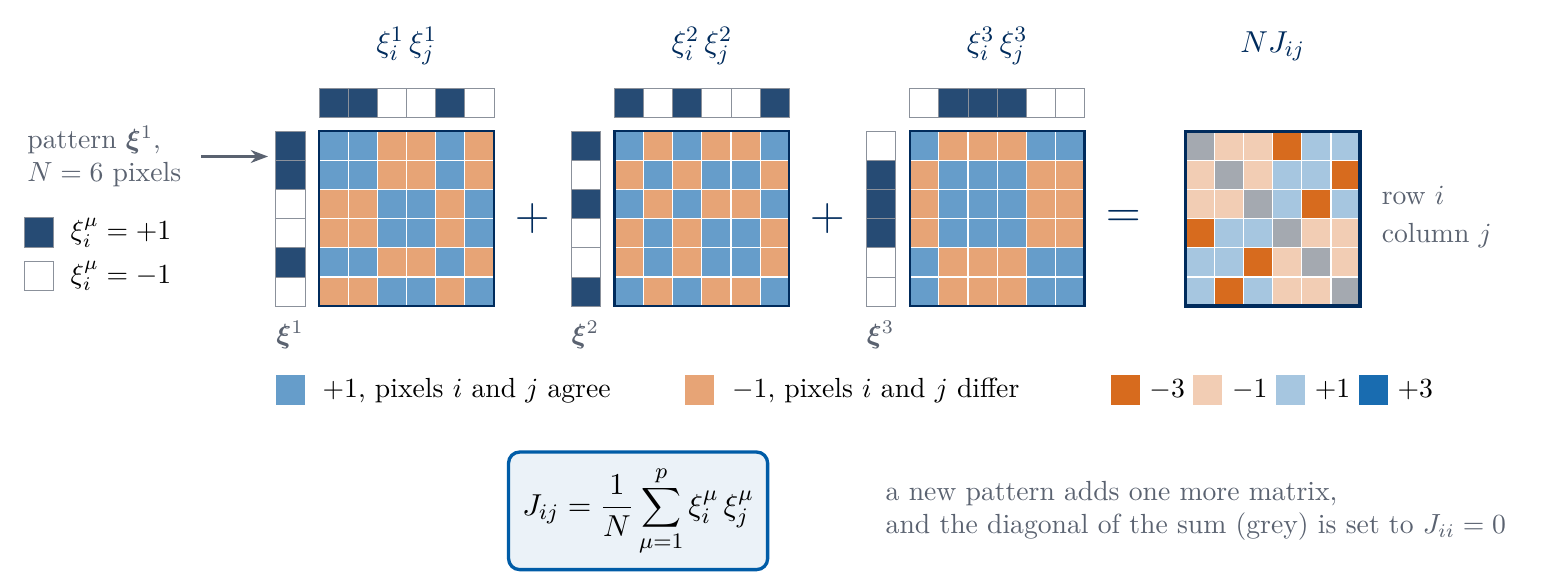

The sketch shows the rule for three patterns of $N=6$ pixels. Each pattern contributes the matrix $\xi_i^\mu\xi_j^\mu$, with the entry $+1$ where the pixels $i$ and $j$ agree and $-1$ where they differ, and the sum of the three matrices is $NJ_{ij}$ with the diagonal set to zero. The sketch draws $\xi=+1$ in navy and $\xi=-1$ in white, whereas the digit figures of this notebook show $+1$ as white background and $-1$ as black ink.

With several patterns the argument of Section 3 no longer guarantees that each pattern is a fixed point, because every pattern contributes to the field of every spin. We therefore store ten random patterns of 1000 spins, in which every spin is $\pm1$ with equal probability and independent of the others, and check whether each of them is a fixed point.

The next cell defines three functions that the rest of the notebook uses. All of them hold the patterns in an array `xi` of shape `(p, N)`, with one pattern per row. The product `xi.T @ xi` has shape `(N, N)`, and its entry $(i,j)$ is $\sum_\mu\xi_i^\mu\xi_j^\mu$, which is the sum in equation (7).

In [9]:
def random_patterns(p, N, rng):
    # rng.integers(0, 2, ...) gives 0 or 1, and 2 * x - 1 turns these into -1 or +1. Shape (p, N).
    return 2.0 * rng.integers(0, 2, size=(p, N)) - 1.0

def hebb(xi):
    # Hebbian couplings, equation (7). xi has shape (p, N), so xi.T @ xi has shape (N, N).
    J = xi.T @ xi / xi.shape[1]
    np.fill_diagonal(J, 0.0)
    return J

def overlaps(xi, s):
    # overlap m of equation (6) with every pattern, shape (p,)
    return xi @ s / xi.shape[1]

xi = random_patterns(10, 1000, rng)
J = hebb(xi)
# xi @ J has shape (p, N). Entry (nu, i) is sum_j xi_j^nu J_ji, which equals the field phi_i in the configuration s = xi^nu
# because J is symmetric.
# Multiplying entry by entry with xi gives xi_i^nu phi_i, which is positive when spin i of pattern nu is stable.
aligned = xi * (xi @ J) > 0                                  # boolean array, shape (p, N)
print(f"10 random patterns of 1000 spins: {int(aligned.all(axis=1).sum())} of 10 are fixed points")   # all(axis=1) tests each row
pattern_overlaps = xi @ xi.T / 1000                          # shape (p, p), ones on the diagonal
random_overlap_max = float(np.abs(pattern_overlaps - np.eye(10)).max())
print(f"largest overlap between two different patterns: {random_overlap_max:.3f}")

10 random patterns of 1000 spins: 10 of 10 are fixed points
largest overlap between two different patterns: 0.076


All ten patterns are fixed points. Two different random patterns agree on about half of their spins, and their overlap is of order $1/\sqrt N$, here at most $0.08$. Section 5 shows that these overlaps between the patterns disturb the field on a stored pattern.

## 5. Signal and cross-talk

To test whether a stored pattern $\boldsymbol\xi^\nu$ is a fixed point, we use the couplings (7), with which the field on spin $i$ in the configuration $\mathbf s=\boldsymbol\xi^\nu$ is
$$\phi_i=\frac1N\sum_{\mu=1}^{p}\xi_i^\mu\sum_{j\neq i}\xi_j^\mu\xi_j^\nu .$$
The spin is stable if the field has the sign of $\xi_i^\nu$, which is the condition $\xi_i^\nu \phi_i>0$. We separate the term $\mu=\nu$, in which $\xi_j^\nu\xi_j^\nu=1$ for each of the $N-1$ values of $j$, from the terms of the other patterns,
$$\xi_i^\nu \phi_i=\underbrace{\frac{N-1}{N}}_{\text{signal}}+\underbrace{\frac1N\sum_{\mu\neq\nu}\sum_{j\neq i}\xi_i^\nu\xi_i^\mu\,\xi_j^\mu\xi_j^\nu}_{\text{cross-talk }C_i^\nu} . \tag{8}$$
The signal is close to one and comes from the pattern under test. The cross-talk
$$C_i^\nu=\frac1N\sum_{\mu\neq\nu}\sum_{j\neq i}\xi_i^\nu\xi_i^\mu\,\xi_j^\mu\xi_j^\nu \tag{9}$$
comes from all other patterns. The sum over $j$ is almost the overlap $q_{\mu\nu}=\tfrac1N\sum_j\xi_j^\mu\xi_j^\nu$ of the two patterns, and carrying out the sum gives
$$C_i^\nu=\sum_{\mu\neq\nu}\xi_i^\nu\xi_i^\mu\,q_{\mu\nu}-\frac{p-1}{N} ,$$
so every other pattern disturbs spin $i$ in proportion to its overlap with the pattern under test. Small overlaps between the patterns therefore keep the cross-talk small. For random patterns each of the $(p-1)(N-1)$ terms of equation (9) takes the values $\pm1$ with equal probability. Each term contains its own factor $\xi_j^\mu$, which appears in no other term, so the terms behave as independent signs. A sum of $K$ such signs has zero mean and variance $K$, so $C_i^\nu$ has zero mean and the variance $(p-1)(N-1)/N^2\approx p/N$, and by the central limit theorem its distribution is close to a Gaussian. The ratio $\alpha=p/N$ is called the load of the network. The spin points against its field when $C_i^\nu<-(N-1)/N\approx-1$, which has the probability of a Gaussian tail,
$$P_{\rm flip}=\frac{1}{\sqrt{2\pi\alpha}}\int_{-\infty}^{-1}e^{-x^2/2\alpha}\,dx=\frac12\,\mathrm{erfc}\Big(\frac{1}{\sqrt{2\alpha}}\Big) , \tag{10}$$
with the complementary error function $\mathrm{erfc}(x)=\tfrac{2}{\sqrt\pi}\int_x^\infty e^{-t^2}dt$. A pattern is stable as long as the signal exceeds the cross-talk for almost all spins, which requires a typical cross-talk $\sqrt\alpha$ well below one.

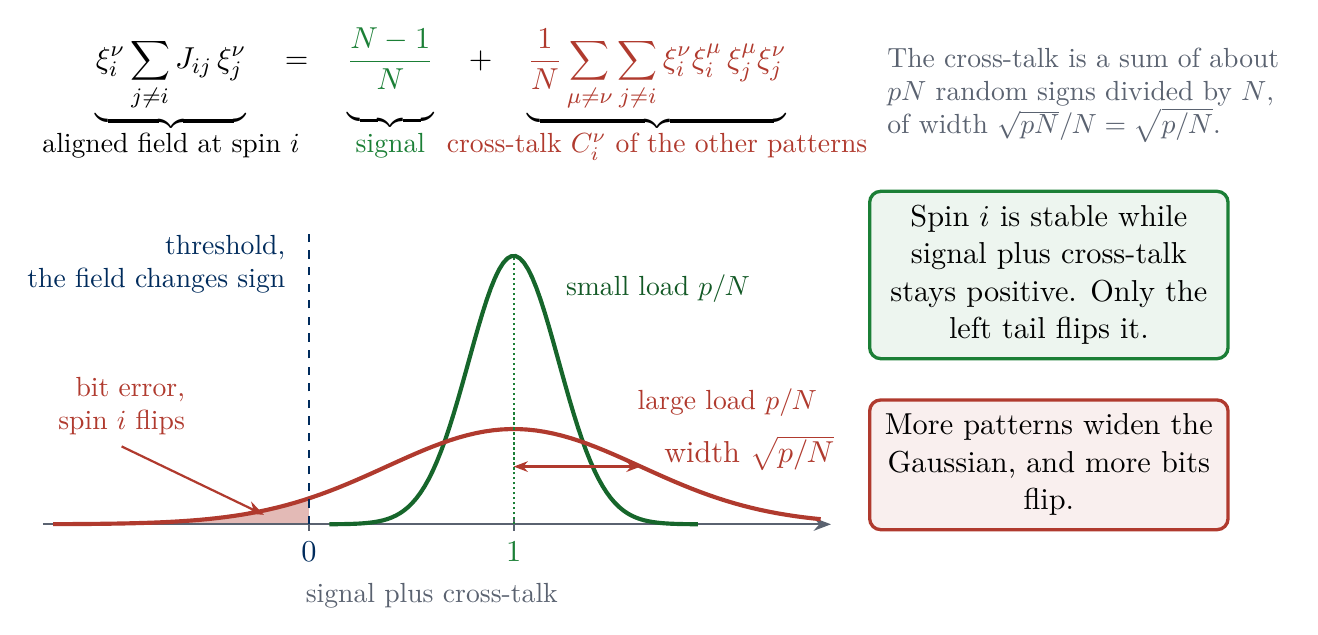

The sketch shows the distribution of $\xi_i^\nu \phi_i$, the signal plus the cross-talk, as a Gaussian centred at one with the width $\sqrt{p/N}$. The spin flips when this quantity is negative, which is the shaded tail, and a larger load widens the Gaussian and enlarges the tail.

We measure the cross-talk for $N=1000$ and six loads. For every load we draw five sets of patterns, evaluate $\xi_i^\nu \phi_i$ for all patterns and all spins, and subtract the signal. We compare the variance with $p/N$ and the fraction of spins that point against their field with equation (10). The printed table also lists the same Gaussian tail evaluated with the variance $(p-1)(N-1)/N^2$ and the threshold $(N-1)/N$ of the finite network. The error bar of the measured fraction is the square root of the number of such spins divided by the number of spins examined. The figure shows the histogram of the cross-talk at one load and the fraction of misaligned spins against the load.

The quantity $N\xi_i^\nu\phi_i$ is an integer, so for even $p$ a few spins have a field equal to zero and sit on the threshold between the two cases. Rounding errors would decide on which side such a spin falls, so we count each of them with the weight one half, the usual correction when a Gaussian integral that ends at the threshold approximates a sum over discrete values. This is a convention for comparing the count with equation (10). The dynamics itself leaves a spin with zero field unchanged. The printed table lets us judge the convention, since it also gives the deviation obtained when zero-field spins are not counted at all.

The next cell computes, for every load and every set of patterns, the array with the entries $\xi_i^\nu\phi_i$ of equation (8), of shape `(p, N)`. All sets are joined in one long vector `alignment`. Subtracting the signal from it gives the cross-talk (9), in the line `C = alignment - SIGNAL`. The dictionary `crosstalk` receives the variance and the counts for every load. The two following cells print the table and draw the figure.

In [10]:
def tail(alpha):
    return 0.5 * math.erfc(1 / math.sqrt(2 * alpha))         # P_flip of equation (10)

def tail_finite(p, N):
    # the same Gaussian tail with the variance (p - 1)(N - 1)/N^2 and the threshold (N - 1)/N of a finite network
    return 0.5 * math.erfc(math.sqrt((N - 1) / (2 * (p - 1))))

def alignment_of_stored_patterns(p, N, rng):
    xi = random_patterns(p, N, rng)
    return xi * (xi @ hebb(xi))                              # xi_i^nu phi_i for every pattern nu and spin i, shape (p, N)

N_CT, SETS_CT = 1000, 5
LOADS_CT = (0.08, 0.1, 0.138, 0.2, 0.3, 0.5)
SIGNAL = (N_CT - 1) / N_CT                                   # the first term of equation (8)
crosstalk = {}
for alpha in LOADS_CT:
    p = int(round(alpha * N_CT))
    sets = [alignment_of_stored_patterns(p, N_CT, rng).ravel() for _ in range(SETS_CT)]   # ravel makes one long vector
    alignment = np.concatenate(sets)                         # all values xi_i^nu phi_i at this load
    C = alignment - SIGNAL                                   # the cross-talk, equation (9)

    N_alignment = np.rint(N_CT * alignment)                  # N xi_i^nu phi_i is an integer, and rint removes rounding errors
    against = int(np.sum(N_alignment < 0))                   # a boolean array sums to the number of its True entries
    on_threshold = int(np.sum(N_alignment == 0))             # spins with zero field
    count = against + 0.5 * on_threshold

    crosstalk[alpha] = dict(p=p, variance=float(C.var()), count=count, against=against, zero_field=on_threshold, total=C.size,
                            fraction=count / C.size, error=math.sqrt(count) / C.size, gaussian=tail(alpha), gaussian_finite_N=tail_finite(p, N_CT))
    if alpha == 0.2:
        C_hist = C                                           # kept for the histogram

In [11]:
print(f"N = {N_CT}, {SETS_CT} independent sets of patterns per load")
print(f"{'load':>6s} {'p':>4s} {'variance':>9s} {'p/N':>6s} {'misaligned spins':>21s} {'zero field':>10s} {'fraction':>9s} {'error':>8s} {'Gaussian':>9s} {'finite N':>9s}")
for alpha, v in crosstalk.items():
    print(f"{alpha:6.3f} {v['p']:4d} {v['variance']:9.4f} {v['p'] / N_CT:6.3f} {v['count']:10.1f} of {v['total']:7d} {v['zero_field']:10d}"
          f" {v['fraction']:9.5f} {v['error']:8.5f} {v['gaussian']:9.5f} {v['gaussian_finite_N']:9.5f}")

# deviations of the measured fractions from the two formulas, in units of the error bar
dev = {a: (v["fraction"] - v["gaussian"]) / v["error"] for a, v in crosstalk.items()}
dev_finite = {a: (v["fraction"] - v["gaussian_finite_N"]) / v["error"] for a, v in crosstalk.items()}
dev_no_zero = {a: (v["against"] / v["total"] - v["gaussian_finite_N"]) / v["error"] for a, v in crosstalk.items()}
print("measured fraction minus equation (10), in error bars:      " + " ".join(f"{dev[a]:+.1f}" for a in LOADS_CT))
print("measured fraction minus the finite-N value, in error bars: " + " ".join(f"{dev_finite[a]:+.1f}" for a in LOADS_CT))
print("the same, with zero-field spins not counted:               " + " ".join(f"{dev_no_zero[a]:+.1f}" for a in LOADS_CT))

N = 1000, 5 independent sets of patterns per load
  load    p  variance    p/N      misaligned spins zero field  fraction    error  Gaussian  finite N
 0.080   80    0.0794  0.080       67.5 of  400000          1   0.00017  0.00002   0.00020   0.00019
 0.100  100    0.0983  0.100      368.0 of  500000          4   0.00074  0.00004   0.00078   0.00075
 0.138  138    0.1366  0.138     2384.5 of  690000         33   0.00346  0.00007   0.00355   0.00346
 0.200  200    0.1990  0.200    12575.0 of 1000000        152   0.01257  0.00011   0.01267   0.01253
 0.300  300    0.2987  0.300    50831.5 of 1500000        661   0.03389  0.00015   0.03394   0.03378
 0.500  500    0.4971  0.500   195948.5 of 2500000        829   0.07838  0.00018   0.07865   0.07855
measured fraction minus equation (10), in error bars:      -1.7 -1.2 -1.4 -0.9 -0.4 -1.5
measured fraction minus the finite-N value, in error bars: -0.9 -0.2 -0.1 +0.4 +0.7 -0.9
the same, with zero-field spins not counted:               -1.0 -

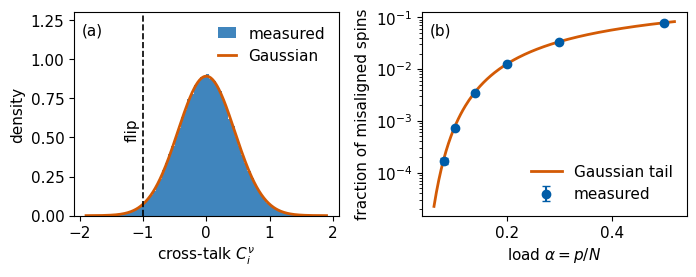

In [12]:
plot_crosstalk(C_hist, crosstalk, LOADS_CT)

Panel (a) shows the histogram of the cross-talk at the load $\alpha=0.2$ together with the Gaussian of variance $0.2$, and the dashed line marks the value $-1$ below which a spin flips. The measured variance is $0.199$, and the table shows the same agreement with $p/N$ at every load. Panel (b) shows the fraction of spins of the stored patterns that point against their field on a logarithmic axis, against the load. The measured fraction grows from $0.017$ per cent at the load $0.08$ to $7.8$ per cent at the load $0.5$ and follows equation (10), the curve labelled Gaussian tail. At the load $0.138$ it is $0.35$ per cent. The measured values lie below equation (10) at all six loads, by up to $1.7$ error bars. The Gaussian tail with the variance and the threshold of the finite network, listed in the last column, differs from the measurement by at most $0.9$ error bars, so the small deficit is an effect of the finite size $N=1000$. Without the zero-field spins the deviation from the finite-size value reaches $1.9$ error bars and all six values are negative, which is why we give these spins the weight one half.

These fractions describe the first update from a stored pattern. A spin that flips changes the fields of all other spins, which can cause further flips or leave the configuration close to the pattern. The fraction (10) alone therefore does not give the load at which recall fails. Section 8 measures this load and shows the cascade of flips directly.

## 6. Energy and recall in terms of overlaps

The overlap of a configuration with pattern $\mu$ is
$$m_\mu(\mathbf s)=\frac1N\sum_{i=1}^{N}\xi_i^\mu s_i , \tag{11}$$
the quantity $m$ of Section 3 for each stored pattern. It measures how close the configuration is to the pattern, since $m_\mu=1-2d_\mu/N$ when $d_\mu$ spins differ from pattern $\mu$. The energy depends on the configuration only through these $p$ numbers. Inserting the couplings (7) into the energy (1) gives
$$E=-\frac1{2N}\sum_{\mu=1}^{p}\sum_{i\neq j}\xi_i^\mu s_i\,\xi_j^\mu s_j .$$
For each pattern the sum over $i\neq j$ is the square of the full sum minus its diagonal terms, $\sum_{i\neq j}u_iu_j=\big(\sum_iu_i\big)^2-\sum_iu_i^2$ with $u_i=\xi_i^\mu s_i=\pm1$, which equals $(Nm_\mu)^2-N$. Therefore
$$E(\mathbf s)=-\frac N2\sum_{\mu=1}^{p}m_\mu^2+\frac p2 . \tag{12}$$
The energy is low when the configuration has a large overlap with one of the stored patterns. At a stored pattern of a random set one overlap equals one and the other $p-1$ overlaps are of order $1/\sqrt N$, so each of them contributes about $-\tfrac N2\cdot\tfrac1N=-\tfrac12$ to the energy. These contributions nearly cancel the constant $p/2$, which leaves $E\approx-N/2$ with fluctuations from the sizes of the small overlaps. A random configuration has all $p$ overlaps of order $1/\sqrt N$, the same cancellation applies to all of them, and its energy is close to zero. Each stored pattern is thus the bottom of a valley of depth about $N/2$. The same substitution in equation (2) gives the field $\phi_i=\sum_\mu\xi_i^\mu m_\mu-(p/N)s_i$, so each pattern adds to the field a term that points towards its own value $\xi_i^\mu$ and is weighted by its overlap.

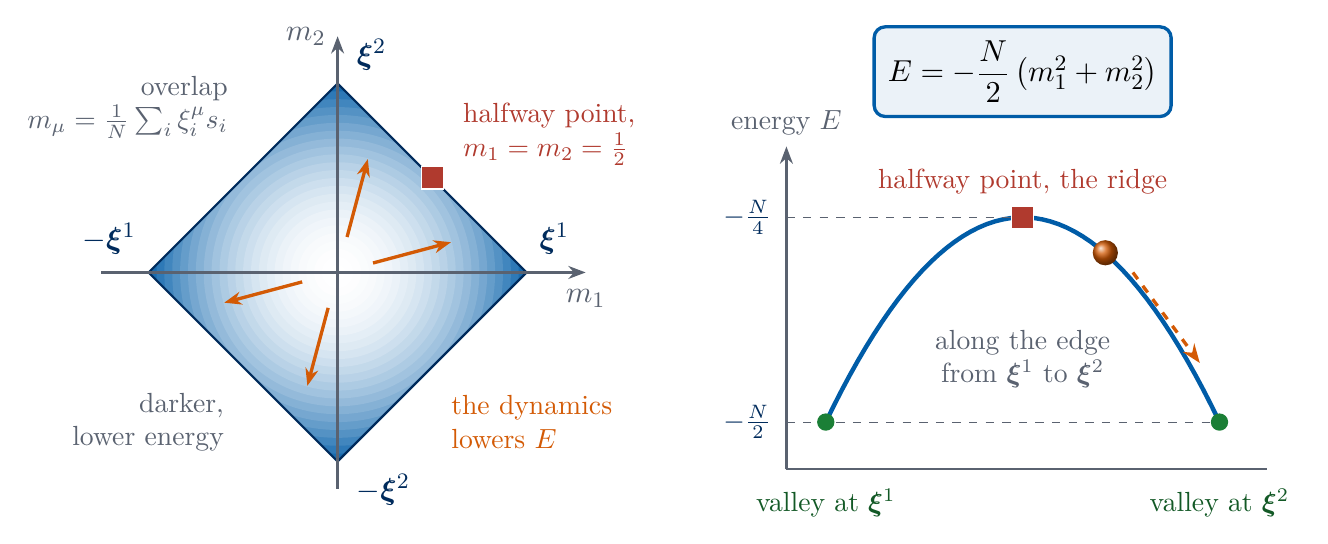

The sketch shows the case of two stored patterns. The left panel is the plane of the two overlaps, in which the energy decreases towards the four corners $\pm\boldsymbol\xi^1$ and $\pm\boldsymbol\xi^2$. For two orthogonal patterns the overlaps obey $|m_1|+|m_2|\le1$, which is why the allowed region is a diamond, and the sketch leaves out the constant $p/2$. The right panel shows the energy along the edge from $\boldsymbol\xi^1$ to $\boldsymbol\xi^2$, where the halfway point with $m_1=m_2=\tfrac12$ lies on the ridge of energy $-N/4$ between two valleys of energy $-N/2$.

We check equation (12) on 200 random configurations and on the stored patterns for $N=1000$ and $p=30$, and we then follow a single recall. The cue is the first pattern with 25 per cent of its spins flipped, so its overlap with that pattern is $0.5$. After every flip we record all 30 overlaps and the energy, and the figure shows both against the number of flips.

The next cell first compares the two expressions for the energy. The array `states` has shape `(230, N)`, with one configuration per row, so `states @ xi.T / N` has shape `(230, p)` and contains every overlap $m_\mu$ of every configuration. Squaring it and summing along the rows (`axis=1`) gives $\sum_\mu m_\mu^2$ per configuration, which enters equation (12). The second half of the cell runs the recall. The array `m_run` has shape `(flips + 1, p)`, so column $\mu$ is the history of the overlap $m_\mu$.

equation (12) on 230 configurations: largest difference 6.8e-13
energy of the stored patterns: between -513.3 and -491.0; -N/2 = -500
single run: 250 flips, overlap with pattern 1 0.500 -> 1.000, largest other overlap 0.060 -> 0.102 (largest during the run 0.102), energy -121.7 -> -502.8, stored pattern -502.8


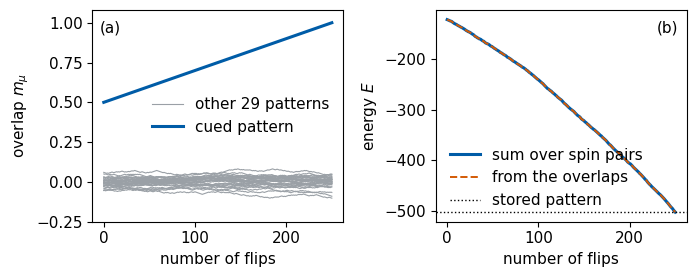

In [13]:
N_OV, P_OV = 1000, 30
xi = random_patterns(P_OV, N_OV, rng)
J = hebb(xi)

# Equation (12) against the direct sum (1), on 200 random configurations and on the 30 stored patterns
states = np.vstack([random_patterns(200, N_OV, rng), xi])    # np.vstack stacks the rows, shape (230, N)
E_direct = np.array([energy(J, s) for s in states])
m_states = states @ xi.T / N_OV                              # overlaps, shape (230, p)
E_overlap = -N_OV / 2 * np.sum(m_states ** 2, axis=1) + P_OV / 2
identity_error = float(np.abs(E_direct - E_overlap).max())
print(f"equation (12) on {len(states)} configurations: largest difference {identity_error:.1e}")
print(f"energy of the stored patterns: between {E_direct[200:].min():.1f} and {E_direct[200:].max():.1f}; -N/2 = {-N_OV / 2:.0f}")

# Recall of pattern 1 from a cue with 25 per cent of its spins flipped, followed flip by flip
cue = flip_fraction(xi[0], 0.25, rng)
s_end, flips = relax(J, cue, rng, record=True)
E_run, m_run = replay(J, cue, flips, xi)                     # E_run has shape (flips + 1,), m_run shape (flips + 1, p)
E_from_m = -N_OV / 2 * np.sum(m_run ** 2, axis=1) + P_OV / 2 # equation (12) along the run
others = np.abs(m_run[:, 1:])                                # all rows, columns 1 to p - 1: the patterns that were not cued
E_pattern = energy(J, xi[0])
print(f"single run: {len(flips)} flips, overlap with pattern 1 {m_run[0, 0]:.3f} -> {m_run[-1, 0]:.3f}, largest other overlap"
      f" {others[0].max():.3f} -> {others[-1].max():.3f} (largest during the run {others.max():.3f}),"
      f" energy {E_run[0]:.1f} -> {E_run[-1]:.1f}, stored pattern {E_pattern:.1f}")
plot_overlaps(m_run, E_run, E_from_m, E_pattern)

In [14]:
REPORT["recall_run"] = dict(flips=len(flips), m_cue=float(m_run[0, 0]), m_end=float(m_run[-1, 0]), other_max_cue=float(others[0].max()),
                            other_max_end=float(others[-1].max()), other_max_run=float(others.max()), E_cue=float(E_run[0]), E_end=float(E_run[-1]),
                            E_pattern=float(E_pattern), formula_error=float(np.abs(E_run - E_from_m).max()))

Equation (12) agrees with the direct sum (1) to rounding errors. Panel (a) shows the overlaps of this single run against the number of flips. The overlap with the cued pattern rises linearly from $0.5$ to $1$ in 250 flips, one for each wrong spin, while the overlaps with the other 29 patterns stay below $0.11$ in magnitude during the whole run. Panel (b) shows the energy, which falls from $-122$ to $-503$, the energy of the stored pattern (dotted line). The solid curve is the sum over spin pairs of equation (1), and the dashed curve is equation (12) evaluated with the recorded overlaps, which lies on top of it. In this run the recall is a descent into the valley of the pattern that had the largest overlap with the cue.

## 7. Recall of images from masked and noisy cues

The patterns are now the digit images described in the introduction, each with $N=784$ pixels. We store the digits 3 and 8 with the Hebbian rule (7) and test two kinds of cue. In the masked cue the lower half of the digit 3 is removed, which we represent by setting these pixels to the background value $+1$. Lab 078a gave such pixels the value 0, and the end of this section compares the two choices. In the noisy cue 25 per cent of the pixels of the digit 8 are flipped at random positions. The network receives only the cue and no information on the digit from which it came. Each row of the figure is a single run and shows the cue, two intermediate configurations, the fixed point and, for comparison, the stored digit. 

The next cell builds the two cues and runs both recalls. Entries 392 to 783 of an image vector are the lower half of the image, because `reshape` stores the image row after row, so the assignment `cue_masked[N_IMG // 2:] = 1.0` sets the lower half to the background. The list `image_runs` keeps, for each cue, what the figure needs.

masked cue of the digit 3: overlaps with (3, 8) = (0.895, 0.781) -> (1.000, 0.778) after 41 flips, wrong pixels 0
noisy cue of the digit 8: overlaps with (3, 8) = (0.380, 0.500) -> (0.778, 1.000) after 196 flips, wrong pixels 0


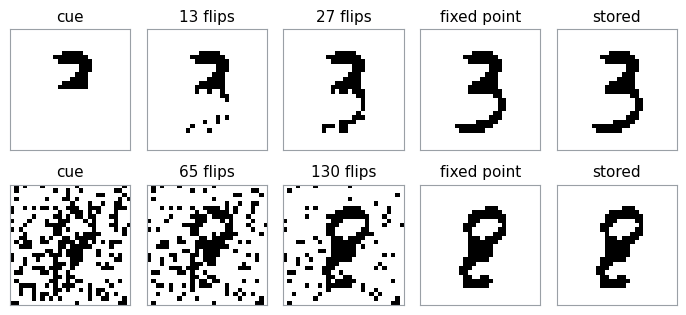

In [15]:
PAIR = (3, 8)
xi_pair = xi_digits[list(PAIR)]                              # indexing with a list selects these rows, shape (2, N)
J_pair = hebb(xi_pair)
q_pair = float(xi_pair[0] @ xi_pair[1] / N_IMG)              # overlap between the two stored digits

cue_masked = xi_pair[0].copy()
cue_masked[N_IMG // 2:] = 1.0                                # lower half of the digit 3 masked, set to background
cue_noisy = flip_fraction(xi_pair[1], 0.25, rng)             # digit 8 with 25 per cent of the pixels flipped

image_runs = []
for name, cue, target in (("masked", cue_masked, 0), ("noisy", cue_noisy, 1)):
    s_end, flips = relax(J_pair, cue, rng, record=True)
    E, m = replay(J_pair, cue, flips, xi_pair)               # m has shape (flips + 1, 2)
    image_runs.append(dict(name=name, cue=cue, flips=flips, s_end=s_end, stored=xi_pair[target], m_cue=m[0], m_end=m[-1]))
    print(f"{name} cue of the digit {PAIR[target]}: overlaps with ({PAIR[0]}, {PAIR[1]}) = ({m[0, 0]:.3f}, {m[0, 1]:.3f}) ->"
          f" ({m[-1, 0]:.3f}, {m[-1, 1]:.3f}) after {len(flips)} flips, wrong pixels {int(np.sum(s_end != xi_pair[target]))}")
plot_digit_recall([(run["cue"], run["flips"], run["stored"]) for run in image_runs])

We then repeat the same two tests for both digits of every pair among the ten digits, which gives four cues per pair and 45 pairs. A pair counts as restored when all its four cues end at the cued digit without a wrong pixel. For each failure the list `pair_failures` keeps the overlaps of the cue and of the fixed point with the two digits of the pair.

In [16]:
pairs_restored, pairs_tested, pair_failures = 0, 0, []
for d1 in range(10):
    for d2 in range(d1 + 1, 10):                             # every pair of different digits once
        x = xi_digits[[d1, d2]]                              # the two patterns, shape (2, N)
        J_two = hebb(x)
        all_restored = True
        for k in range(2):                                   # k selects the digit of the pair that is cued
            masked = x[k].copy()
            masked[N_IMG // 2:] = 1.0
            noisy = flip_fraction(x[k], 0.25, rng)
            for kind, cue in (("masked", masked), ("noisy", noisy)):
                s_end = relax(J_two, cue, rng)
                if not np.array_equal(s_end, x[k]):          # True only if all N entries agree
                    all_restored = False
                    pair_failures.append(dict(pair=[d1, d2], cued_digit=[d1, d2][k], cue=kind, cue_overlaps=overlaps(x, cue).tolist(),
                                              final_overlaps=overlaps(x, s_end).tolist()))
        pairs_restored += all_restored                       # True counts as 1
        pairs_tested += 1
print(f"pairs of digits with all four cues restored without a wrong pixel: {pairs_restored} of {pairs_tested}")
for f in pair_failures:
    print(f"   pair {tuple(f['pair'])}, {f['cue']} cue of the digit {f['cued_digit']}: overlaps of the cue with the pair"
          f" ({f['cue_overlaps'][0]:.3f}, {f['cue_overlaps'][1]:.3f}), of the fixed point ({f['final_overlaps'][0]:.3f}, {f['final_overlaps'][1]:.3f})")

pairs of digits with all four cues restored without a wrong pixel: 39 of 45
   pair (0, 5), masked cue of the digit 0: overlaps of the cue with the pair (0.819, 0.821), of the fixed point (0.727, 1.000)
   pair (1, 6), masked cue of the digit 6: overlaps of the cue with the pair (0.857, 0.821), of the fixed point (1.000, 0.760)
   pair (4, 6), masked cue of the digit 6: overlaps of the cue with the pair (0.849, 0.821), of the fixed point (1.000, 0.788)
   pair (5, 6), masked cue of the digit 6: overlaps of the cue with the pair (0.890, 0.821), of the fixed point (1.000, 0.747)
   pair (6, 7), masked cue of the digit 6: overlaps of the cue with the pair (0.821, 0.834), of the fixed point (0.737, 1.000)
   pair (6, 9), masked cue of the digit 6: overlaps of the cue with the pair (0.821, 0.827), of the fixed point (0.745, 1.000)


Both cues are restored without a wrong pixel, the masked one after 41 flips and the noisy one after 196. The two stored digits are far from independent, with an overlap of $0.78$, because they share the white background. With two patterns the field of Section 6 is $\phi_i\approx\xi_i^1m_1+\xi_i^2m_2$. A pixel on which the two digits agree takes their common value, and a pixel on which they differ takes the value of the digit with the larger overlap, so the network returns the stored digit that is closer to the cue. Among the 45 pairs of digits, 39 restore all four cues without a wrong pixel. Each of the other 6 pairs fails on one masked cue, and no noisy cue fails. In each of these failures the printed overlaps show that the cue with the masked lower half is closer to the other digit of the pair, and the network returns that digit.

### Two ways of filling masked pixels

Lab 078a started masked pixels at $s_i=0$, called undecided, whereas this section starts them at the background value $+1$. The two choices express different assumptions. A pixel at 0 contributes nothing to the overlaps, so the visible half alone decides which stored image is ahead. A pixel at $+1$ makes the cue a legitimate spin configuration, as the function `relax` requires, but it adds agreement with every digit that has background there. The rule $s_i\phi_i<0$ in `relax` would also never change a spin with $s_i=0$, so an undecided pixel needs a first step of its own.

The next cell compares the two choices on the 90 masked cues of the 45 pairs. The function `relax_from_undecided` visits the undecided pixels once in random order, gives each the sign of its current field, with the background value in the case of a zero field, and then calls `relax`. This test has its own random generator, so it leaves all other numbers of the notebook unchanged.

In [17]:
def relax_from_undecided(J, s, rng):
    s = s.copy()
    for i in rng.permutation(np.flatnonzero(s == 0)):        # the undecided pixels, in random order
        phi_i = J[i] @ s                                     # field of pixel i, equation (2)
        s[i] = -1.0 if phi_i < 0 else 1.0
    return relax(J, s, rng)

rng_masks = np.random.default_rng(7803)
restored_background, restored_undecided, fixed_by_undecided = 0, 0, 0
for d1 in range(10):
    for d2 in range(d1 + 1, 10):
        x = xi_digits[[d1, d2]]
        J_two = hebb(x)
        for k in range(2):
            with_background, with_zeros = x[k].copy(), x[k].copy()
            with_background[N_IMG // 2:] = 1.0
            with_zeros[N_IMG // 2:] = 0.0
            ok_background = np.array_equal(relax(J_two, with_background, rng_masks), x[k])
            ok_undecided = np.array_equal(relax_from_undecided(J_two, with_zeros, rng_masks), x[k])
            restored_background += ok_background
            restored_undecided += ok_undecided
            fixed_by_undecided += ok_undecided and not ok_background
print(f"masked cues restored without a wrong pixel, of 90: background start {restored_background}, undecided start {restored_undecided}")
print(f"cues that fail with the background start and succeed with the undecided start: {fixed_by_undecided}")

masked cues restored without a wrong pixel, of 90: background start 84, undecided start 90
cues that fail with the background start and succeed with the undecided start: 6


The background start restores 84 of the 90 masked cues, and its six failures are those of the pair test above. The undecided start restores all 90, including these six. Filling the masked half with background therefore adds agreement with the digit that has more background there, and this is what sends the six cues to the wrong digit. With undecided pixels the visible half alone sets the overlaps. We keep the background start in the rest of this notebook, because every configuration then consists of spins $\pm1$ and the energy argument of Section 2 applies from the first step, and the failures remain a useful example of a cue that is closer to another pattern.

### Three stored digits

We next add the digit 0 to the digits 3 and 8, start the dynamics at each of the three stored digits, and compare the fixed points. The next cell computes the matrix `q_digits` of the overlaps between all ten digit images, of shape `(10, 10)`. The boolean mask `~np.eye(10, dtype=bool)` is `True` everywhere except on the diagonal, so indexing with it selects the 90 overlaps between different digits. The figure shows the three stored digits next to the configuration at which the dynamics stops.

overlaps between different digits: from 0.58 to 0.89; random patterns of 784 spins would have about 0.04
start at the stored digit 3: 39 flips, final overlaps with (3, 8, 0) = [0.901 0.878 0.768], energy -802.9 -> -849.4
start at the stored digit 8: 48 flips, final overlaps with (3, 8, 0) = [0.901 0.878 0.768], energy -791.1 -> -849.4
start at the stored digit 0: 91 flips, final overlaps with (3, 8, 0) = [0.901 0.878 0.768], energy -728.9 -> -849.4
the three runs end in the same configuration: True


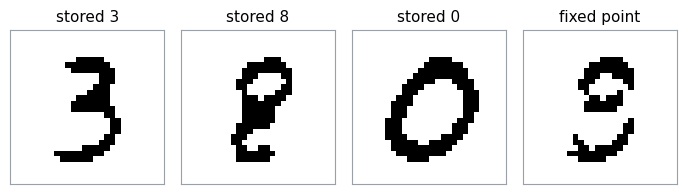

In [18]:
TRIPLE = (3, 8, 0)
xi_triple = xi_digits[list(TRIPLE)]                          # shape (3, N)
J_triple = hebb(xi_triple)
q_digits = xi_digits @ xi_digits.T / N_IMG                   # overlaps between all digit images, shape (10, 10)
q_off = q_digits[~np.eye(10, dtype=bool)]                    # the mask keeps the off-diagonal entries, shape (90,)
print(f"overlaps between different digits: from {q_off.min():.2f} to {q_off.max():.2f};"
      f" random patterns of {N_IMG} spins would have about {1 / np.sqrt(N_IMG):.2f}")

triple_end = []
for k in range(3):
    s0 = xi_triple[k]                                        # the dynamics starts at the stored digit itself
    s_end, flips = relax(J_triple, s0, rng, record=True)
    replay(J_triple, s0, flips)
    triple_end.append(s_end)
    print(f"start at the stored digit {TRIPLE[k]}: {len(flips)} flips, final overlaps with {TRIPLE} = {np.round(overlaps(xi_triple, s_end), 3)},"
          f" energy {energy(J_triple, s0):.1f} -> {energy(J_triple, s_end):.1f}")
print("the three runs end in the same configuration:", all(np.array_equal(triple_end[0], s) for s in triple_end))
plot_digit_blend(xi_triple, TRIPLE, triple_end[0])

None of the three digits is a fixed point. Started at any of them, the dynamics ends in one and the same configuration, an image that blends the three digits, with overlaps $0.90$, $0.88$ and $0.77$ with the digits 3, 8 and 0, and with an energy below that of each stored digit. All digits share the white background, so the overlaps between different digit images range from $0.58$ to $0.89$, whereas random patterns of 784 spins have overlaps of about $0.04$.

To explain the blend with the field formula of Section 6, we start at digit $a$ and call the other two digits $b$ and $c$. At this configuration the overlaps are $m_a=1$, $m_b=q_{ab}$ and $m_c=q_{ac}$, where $q_{ab}$ is the overlap between the digits $a$ and $b$, and $\phi_i=\sum_\mu\xi_i^\mu m_\mu-(p/N)s_i$ gives
$$\xi_i^a\phi_i=1+\xi_i^a\xi_i^b\,q_{ab}+\xi_i^a\xi_i^c\,q_{ac}-\frac3N .$$
Each of the three digits casts a vote at pixel $i$, weighted by its overlap with the current configuration. If digit $a$ agrees with at least one of the others, the right-hand side is positive and the pixel stays. If digit $a$ differs from both others at pixel $i$, then $\xi_i^a\xi_i^b=\xi_i^a\xi_i^c=-1$ and
$$\xi_i^a\phi_i=1-q_{ab}-q_{ac}-\frac3N ,$$
so the pixel is outvoted when $q_{ab}+q_{ac}>1$, up to the small term $3/N$. The pixels that flip are thus those on which digit $a$ is in the minority, and the configuration that remains takes at every pixel the value held by the majority of the three digits,
$$s_i^{\rm maj}=\mathrm{sign}\big(\xi_i^a+\xi_i^b+\xi_i^c\big) .$$

The next cell tests each part of this argument. For every digit it compares the boolean mask of the minority pixels, of shape `(N,)`, with the mask of the misaligned pixels, and it compares the measured value of $\xi_i^a\phi_i$ on the minority pixels with the formula. It then checks that the majority image equals the fixed point. Finally it treats all 120 triples of digits. For each triple it tests that no digit is a fixed point and that the majority image is one, and it runs the dynamics from each of the three digits, which gives 360 runs with their own random generator. It also evaluates the case in which all ten digits are stored.

In [19]:
q_triple = xi_triple @ xi_triple.T / N_IMG                   # overlaps q_ab between the three stored digits, shape (3, 3)
for a in range(3):
    others = [b for b in range(3) if b != a]                 # the other two digits
    q_sum = q_triple[a, others].sum()                        # q_ab + q_ac
    # xi_triple[others] != xi_triple[a] compares both rows with digit a, shape (2, N); all(axis=0) asks for both at each pixel
    minority = np.all(xi_triple[others] != xi_triple[a], axis=0)
    alignment = xi_triple[a] * (J_triple @ xi_triple[a])     # xi_i^a phi_i at the start, shape (N,)
    misaligned = alignment < 0
    measured = alignment[minority]                           # the boolean mask keeps only the minority pixels
    print(f"digit {TRIPLE[a]}: q_ab + q_ac = {q_sum:.3f}, {minority.sum()} minority pixels, {misaligned.sum()} misaligned pixels,"
          f" same pixels: {np.array_equal(minority, misaligned)}, xi phi on them {measured.max():.3f} (formula {1 - q_sum - 3 / N_IMG:.3f})")

majority = np.sign(xi_triple.sum(axis=0))                    # the sum of three values +-1 is odd, so its sign is never zero
print("the fixed point equals the pixelwise majority of the three digits:", np.array_equal(majority, triple_end[0]))

digit 3: q_ab + q_ac = 1.446, 39 minority pixels, 39 misaligned pixels, same pixels: True, xi phi on them -0.450 (formula -0.450)
digit 8: q_ab + q_ac = 1.423, 48 minority pixels, 48 misaligned pixels, same pixels: True, xi phi on them -0.427 (formula -0.427)
digit 0: q_ab + q_ac = 1.314, 91 minority pixels, 91 misaligned pixels, same pixels: True, xi phi on them -0.318 (formula -0.318)
the fixed point equals the pixelwise majority of the three digits: True


In [20]:
# All 120 triples of digits. This loop has its own generator, so that `rng` is not advanced.
rng_triples = np.random.default_rng(7802)
triples_blended, starts_reaching_majority, q_sum_min = 0, 0, np.inf
for d1 in range(10):
    for d2 in range(d1 + 1, 10):
        for d3 in range(d2 + 1, 10):
            x = xi_digits[[d1, d2, d3]]                      # shape (3, N)
            J3 = hebb(x)
            q3 = x @ x.T / N_IMG
            q_sum_min = min(q_sum_min, float((q3.sum(axis=1) - 1).min()))   # each row sum contains the diagonal entry 1
            maj3 = np.sign(x.sum(axis=0))
            # any(...) is True if at least one of the three digits has xi_i phi_i > 0 at every pixel, i.e. is a fixed point
            no_digit_stable = not any(np.all(row * (J3 @ row) > 0) for row in x)
            majority_stable = np.all(maj3 * (J3 @ maj3) > 0)
            triples_blended += bool(no_digit_stable and majority_stable)
            starts_reaching_majority += sum(np.array_equal(relax(J3, row, rng_triples), maj3) for row in x)
print(f"triples with no stable digit and a stable majority image: {triples_blended} of 120; smallest q_ab + q_ac = {q_sum_min:.2f}")
print(f"runs started at a stored digit that end at the majority image: {starts_reaching_majority} of 360")

J_ten = hebb(xi_digits)
ten_stable = int(sum(np.all(row * (J_ten @ row) > 0) for row in xi_digits))
print(f"all ten digits stored: {ten_stable} of 10 are fixed points")

triples with no stable digit and a stable majority image: 120 of 120; smallest q_ab + q_ac = 1.18
runs started at a stored digit that end at the majority image: 360 of 360
all ten digits stored: 0 of 10 are fixed points


The three digits have $q_{ab}+q_{ac}$ between $1.31$ and $1.45$, so the condition holds for each of them. The misaligned pixels at each start are the 39, 48 and 91 pixels on which that digit is in the minority, the value of $\xi_i^a\phi_i$ on them is the one given by the formula, and the fixed point is the pixelwise majority of the three digits. In all 120 triples of digits, whose smallest $q_{ab}+q_{ac}$ is $1.18$, no digit is a fixed point and the majority image is one, and all 360 runs started at a stored digit end there. When all ten digits are stored none of them is a fixed point. The blended image is thus the mixture state of three patterns, which Section 9 meets again as a spurious minimum for random patterns. For random patterns the overlaps are of order $1/\sqrt N$, the sum $q_{ab}+q_{ac}$ is far below one, and no pixel is outvoted in this way.

The estimates of Section 5 assume uncorrelated patterns, so Section 8 uses random patterns. Section 10 shows a different network that holds all ten digit images and returns each of them from a noisy cue. A short session can stop at this point and leave the storage limit of Section 8 and the spurious memories of Section 9 for home.

## 8. Recall rate against the load

The cross-talk of Section 5 grows with the load, which limits the number of random patterns that the network can hold. The capacity of the network is the largest number of patterns for which each stored pattern still lies close to a stable minimum of the energy. It grows in proportion to $N$, so we state it as a critical load $\alpha_c=p_{\rm max}/N$.

The fraction (10) of misaligned spins at a stored pattern concerns the first update only and is small at every load considered here. A different quantity is the critical load $\alpha_c\approx0.138$ of Ref. [2], obtained for $N\to\infty$ with methods from the statistical mechanics of disordered magnets called spin glasses, which are beyond this notebook. According to Ref. [2] the network has minima with an overlap of about $0.97$ or more with each stored pattern up to this load, and these minima disappear above it. The recall rate that we measure here is a third quantity, the fraction of noisy cues that reach such a minimum in a finite network, and it depends on the noise of the cue and on our threshold for success.

For a given size $N$ and load $\alpha=p/N$ we draw a set of $p$ random patterns, build the couplings (7), and present five cues, each a stored pattern with 10 per cent of its spins flipped. We count a recall as successful if the final overlap with the cued pattern exceeds $0.9$, which means that fewer than 5 per cent of the spins of the fixed point are wrong. The recall rate is the fraction of successful recalls. We repeat this for 40 independent sets of patterns, so every point is an average over 200 recalls, and its error bar is the standard error of the 40 set averages. We use the three sizes $N=250$, $500$ and $1000$. The figure marks $\alpha_c$ by a dashed line. Panel (a) shows the recall rate and panel (b) the mean final overlap against the load.

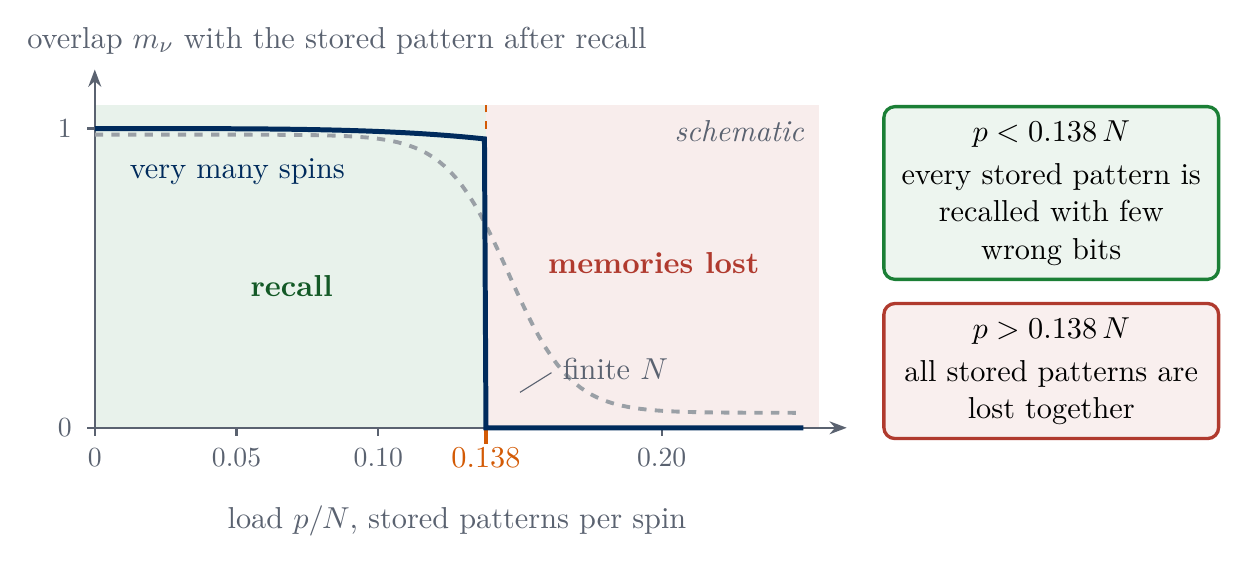

The sketch is a schematic of the result of Ref. [2]. For very many spins the overlap after recall stays close to one below the load $0.138$ and drops abruptly above it. Its dashed curve only indicates that a finite network has a smooth crossover, and the curves that we measure follow below.

The function `recall_at_load` carries out the experiment for one size and one load and returns two arrays of shape `(SETS,)`, the fraction of successful cues per set of patterns and the mean final overlap per set. The next cell then loops over all sizes and loads and stores the mean and the standard error in the dictionary `capacity`.

In [21]:
ALPHA_C = 0.138                     # storage limit of Ref. [2] for N -> infinity, quoted and not measured here
LOADS = np.array([0.04, 0.06, 0.08, 0.10, 0.12, 0.13, 0.14, 0.15, 0.16, 0.18, 0.20, 0.22])
SIZES = (250, 500, 1000)
SETS, CUES, CUE_NOISE, M_SUCCESS = 40, 5, 0.10, 0.90

def recall_at_load(N, alpha, rng):
    p = int(round(alpha * N))
    rate_per_set, overlap_per_set = np.zeros(SETS), np.zeros(SETS)
    for k in range(SETS):
        xi = random_patterns(p, N, rng)                      # a new set of patterns
        J = hebb(xi)
        final_overlaps = np.zeros(CUES)
        for mu in range(CUES):                               # the first CUES patterns are cued; all patterns are equivalent
            cue = flip_fraction(xi[mu], CUE_NOISE, rng)
            final_overlaps[mu] = xi[mu] @ relax(J, cue, rng) / N
        rate_per_set[k] = np.mean(final_overlaps > M_SUCCESS)   # mean of a boolean array is the fraction of True
        overlap_per_set[k] = final_overlaps.mean()
    return rate_per_set, overlap_per_set

In [22]:
t_cap = time.perf_counter()

In [23]:
capacity = {}
for N in SIZES:
    rate = np.zeros((len(LOADS), SETS)); m_final = np.zeros((len(LOADS), SETS))   # rows are loads, columns are sets
    for load_index, alpha in enumerate(LOADS):
        rate[load_index], m_final[load_index] = recall_at_load(N, alpha, rng)
    # mean(1) averages along the columns, so one value per load remains; ddof=1 gives the sample standard deviation
    capacity[N] = dict(rate=rate.mean(1), rate_err=rate.std(1, ddof=1) / np.sqrt(SETS),
                       m=m_final.mean(1), m_err=m_final.std(1, ddof=1) / np.sqrt(SETS))

In [24]:
time_capacity = time.perf_counter() - t_cap

40 sets of patterns x 5 cues = 200 recalls per point, cue with 10% flipped spins, success if the final overlap exceeds 0.9
recall rate (standard error over the sets of patterns); the last three columns are the mean final overlaps
 load     N =  250       N =  500       N = 1000     m( 250) m( 500) m(1000)
 0.04  1.00 (0.00)  1.00 (0.00)  1.00 (0.00)     1.000   1.000   1.000
 0.06  1.00 (0.00)  1.00 (0.00)  1.00 (0.00)     1.000   1.000   1.000
 0.08  1.00 (0.00)  1.00 (0.00)  1.00 (0.00)     0.999   1.000   1.000
 0.10  1.00 (0.00)  0.99 (0.00)  1.00 (0.00)     0.998   0.994   0.998
 0.12  0.97 (0.01)  0.97 (0.01)  0.99 (0.00)     0.985   0.984   0.989
 0.13  0.97 (0.01)  0.94 (0.02)  0.99 (0.01)     0.983   0.965   0.982
 0.14  0.84 (0.03)  0.89 (0.02)  0.88 (0.02)     0.938   0.941   0.930
 0.15  0.73 (0.03)  0.81 (0.02)  0.72 (0.03)     0.895   0.913   0.853
 0.16  0.73 (0.03)  0.66 (0.03)  0.55 (0.03)     0.901   0.830   0.745
 0.18  0.53 (0.04)  0.38 (0.04)  0.16 (0.02)     0.770

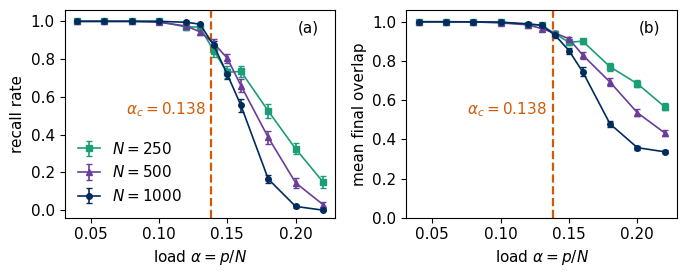

In [25]:
print(f"{SETS} sets of patterns x {CUES} cues = {SETS * CUES} recalls per point, cue with {CUE_NOISE:.0%} flipped spins,"
      f" success if the final overlap exceeds {M_SUCCESS}")
print("recall rate (standard error over the sets of patterns); the last three columns are the mean final overlaps")
print(" load  " + "  ".join(f"   N = {N:4d}  " for N in SIZES) + "   " + " ".join(f"m({N:4d})" for N in SIZES))
for load_index, alpha in enumerate(LOADS):
    rates = "  ".join(f"{capacity[N]['rate'][load_index]:.2f} ({capacity[N]['rate_err'][load_index]:.2f})" for N in SIZES)
    means = " ".join(f"{capacity[N]['m'][load_index]:7.3f}" for N in SIZES)
    print(f"{alpha:5.2f}  {rates}   {means}")
plot_capacity(capacity, LOADS, SIZES, ALPHA_C)

Panel (a) shows the recall rate and panel (b) the mean final overlap with the cued pattern, both against the load, for $N=250$ (teal squares), $500$ (purple triangles) and $1000$ (navy circles). The dashed line marks $\alpha_c=0.138$ of Ref. [2]. Up to the load $0.10$ the recall rate is $0.99$ or higher for all three sizes, and at the load $0.18$ it has fallen to $0.53$, $0.38$ and $0.16$. Above a load of about $0.15$ the fall becomes steeper with growing $N$, which is the behaviour expected if the limit of large networks is a sharp threshold, whereas the small differences between the sizes below this load show no order in $N$. At the load $0.14$, just above $\alpha_c$, the rates still lie between $0.84$ and $0.89$. Our data are compatible with the value $0.138$ and do not determine it.

Recall fades gradually in these finite networks, and for $N=1000$ the rate is $0.88$ at the load $0.14$, $0.55$ at $0.16$, $0.16$ at $0.18$ and zero of 200 recalls at $0.22$, whereas for $N=250$ it is still $0.15$ at $0.22$. A failed recall above the limit also leaves part of the pattern in place, and at the load $0.22$ the mean final overlap is $0.57$ for $N=250$, $0.43$ for $N=500$ and $0.34$ for $N=1000$. The cue started with the overlap $0.8$, and an unrelated configuration of 1000 spins has an overlap of order $1/\sqrt N\approx0.03$. The fixed point therefore stays correlated with the cued pattern, while it misses the threshold $0.9$ that we demand of a recall.

### Cascade of flips above the limit

Section 5 found that only about $0.35$ per cent of the spins of a stored pattern are misaligned at the load $0.138$. These few spins can still destabilise the pattern, because every flip changes the overlap with the pattern and adds to the fields of all other spins, so a spin that was aligned by a small margin can turn misaligned, flip in turn and affect others. In most runs below the limit this process dies out after a few flips, and above the limit it usually grows into a large cascade. Finite networks fluctuate around this picture, as the table below shows.

We observe this by starting the dynamics at a stored pattern itself, with no noise in the cue, for $N=1000$ and nine loads. For every load we draw 20 independent sets of patterns and start at the first pattern of each set. This experiment has its own random generator, so it leaves all other results of the notebook unchanged. The function `overlap_after_each_flip` takes the pattern and the list of flips and returns the overlap with the pattern after 0, 1, 2, ... flips. The dictionary `cascade` receives the mean number of spins that are misaligned at the start, the mean and the largest number of flips until the dynamics stops, and the final overlap, and `cascade_traces` keeps the overlap histories at three loads for the figure.

N = 1000, 20 sets of patterns per load, dynamics started at a stored pattern
  load  misaligned at start    flips  most flips  final overlap            range  final overlap > 0.9
 0.060                  0.0      0.0           0          1.000   1.000 to 1.000                 1.00
 0.080                  0.1      0.1           1          1.000   0.998 to 1.000                 1.00
 0.100                  0.5      0.6           5          0.999   0.990 to 1.000                 1.00
 0.120                  2.0      6.2          60          0.988   0.880 to 1.000                 0.95
 0.138                  3.6      9.9          26          0.981   0.948 to 1.000                 1.00
 0.160                  6.5    138.1         476          0.780   0.308 to 0.992                 0.65
 0.180                  9.6    348.6         592          0.479   0.192 to 0.992                 0.15
 0.200                 11.2    477.6         752          0.327   0.130 to 0.780                 0.00
 0.22

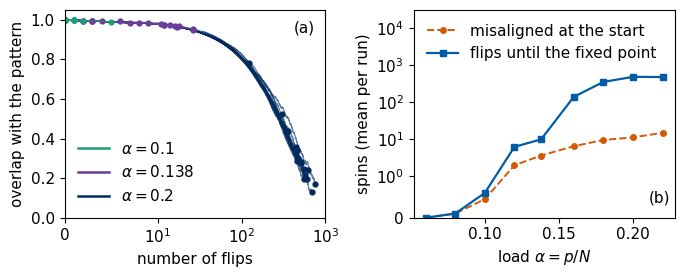

In [26]:
CASCADE_LOADS = (0.06, 0.08, 0.10, 0.12, 0.138, 0.16, 0.18, 0.20, 0.22)
CASCADE_SHOWN = (0.10, 0.138, 0.20)                          # the loads whose single runs appear in the figure
N_CASCADE, SETS_CASCADE = 1000, 20
cascade_rng = np.random.default_rng(7801)                    # separate generator, so that `rng` is not advanced

def overlap_after_each_flip(pattern, flips):
    s = pattern.copy()
    history = [1.0]                                          # the run starts at the pattern, so the overlap is one
    for i in flips:
        s[i] = -s[i]
        history.append(float(pattern @ s / s.size))
    return np.array(history)

cascade, cascade_traces = {}, {alpha: [] for alpha in CASCADE_SHOWN}
for alpha in CASCADE_LOADS:
    p = int(round(alpha * N_CASCADE))
    misaligned_counts, flip_counts, final_m = [], [], []
    for _ in range(SETS_CASCADE):
        xi = random_patterns(p, N_CASCADE, cascade_rng)
        J = hebb(xi)
        pattern = xi[0]
        misaligned_counts.append(int(np.sum(pattern * (J @ pattern) < -TOL)))   # spins that would flip in the first pass
        s_end, flips = relax(J, pattern, cascade_rng, record=True)
        flip_counts.append(len(flips))
        final_m.append(float(pattern @ s_end / N_CASCADE))
        if alpha in CASCADE_SHOWN:
            cascade_traces[alpha].append(overlap_after_each_flip(pattern, flips))
    final_m = np.array(final_m)
    cascade[alpha] = dict(misaligned_at_start=float(np.mean(misaligned_counts)), flips=float(np.mean(flip_counts)), flips_max=int(np.max(flip_counts)),
                          final_overlap=float(final_m.mean()), final_overlap_min=float(final_m.min()), final_overlap_max=float(final_m.max()),
                          fraction_above_success=float(np.mean(final_m > M_SUCCESS)))

print(f"N = {N_CASCADE}, {SETS_CASCADE} sets of patterns per load, dynamics started at a stored pattern")
print(f"{'load':>6s} {'misaligned at start':>20s} {'flips':>8s} {'most flips':>11s} {'final overlap':>14s} {'range':>16s} {'final overlap > 0.9':>20s}")
for alpha, v in cascade.items():
    print(f"{alpha:6.3f} {v['misaligned_at_start']:20.1f} {v['flips']:8.1f} {v['flips_max']:11d} {v['final_overlap']:14.3f}"
          f"   {v['final_overlap_min']:.3f} to {v['final_overlap_max']:.3f} {v['fraction_above_success']:20.2f}")
plot_cascade(cascade, cascade_traces, CASCADE_SHOWN)

Panel (a) shows the overlap with the pattern against the number of flips for the 20 runs at each of three loads, with a dot where each run stops, and panel (b) the two mean numbers against the load. All runs follow nearly the same falling curve, since most flips turn a correct spin into a wrong one and each such flip lowers the overlap by $2/N$, and they differ in how far along it they travel. The flip axis of panel (a) and the spin axis of panel (b) are linear close to zero and logarithmic above. At the load $0.10$ a run has on average $0.5$ misaligned spins at the start and makes $0.6$ flips, so the configuration stays at the pattern. At the load $0.12$, still below the limit, the mean is about 6 flips, but one of the 20 runs makes 60 flips and ends at the overlap $0.88$, while the largest run at the load $0.138$ makes 26 flips. With 20 runs per load this shows that in a finite network a cascade can also begin below the limit. At the load $0.138$ the $3.6$ initially misaligned spins grow to about 10 flips, and every run still ends with an overlap above $0.9$, with a mean of $0.98$. At the load $0.16$ the $6.5$ misaligned spins grow to about 140 flips, and at the load $0.20$ the $11$ misaligned spins grow to about 480 flips, close to half the number of spins. The overlap at the load $0.20$ then ends between $0.13$ and $0.78$ with a mean of $0.33$, and no run keeps an overlap above $0.9$.

Between the loads $0.138$ and $0.20$ the initial number of misaligned spins grows by a factor of about three, whereas the number of flips grows by a factor of about fifty. The small tail of equation (10) therefore starts the failure, and the feedback of the flips on the fields decides whether the pattern survives. The final overlap at the loads $0.20$ and $0.22$, about $0.33$, agrees with the value $0.34$ that the recalls from noisy cues reached in the previous figure. In this network of 1000 spins the crossover from small corrections to a large cascade lies between the loads $0.138$ and $0.18$, around the limit of Ref. [2].

## 9. Spurious memories

The Hebbian landscape has minima that we never stored, called spurious memories, and two kinds follow from the form of the energy (12). The energy is even in the overlaps, so the inverted pattern $-\boldsymbol\xi^\mu$ has the energy of the pattern and is a minimum as well. A mixture state of three patterns takes at every spin the value held by the majority of them,
$$s_i^{\rm mix}=\mathrm{sign}\big(\xi_i^1+\xi_i^2+\xi_i^3\big) . \tag{13}$$
For random patterns $\xi_i^1$ differs from the majority only if both other patterns differ from it, which has the probability $\tfrac14$. The mixture state therefore has the overlap $\tfrac34-\tfrac14=\tfrac12$ with each of the three patterns, and by equation (12) its energy is $E\approx-\tfrac N2\cdot3\cdot\tfrac14=-\tfrac{3N}{8}$. This lies above the energy $-N/2$ of a stored pattern and far below the energy of a random configuration. Section 7 found this state for three digit images, where strongly overlapping patterns made it the only attractor of the three starts. Mixture states of any odd number of patterns are local minima of this kind at small loads [5].

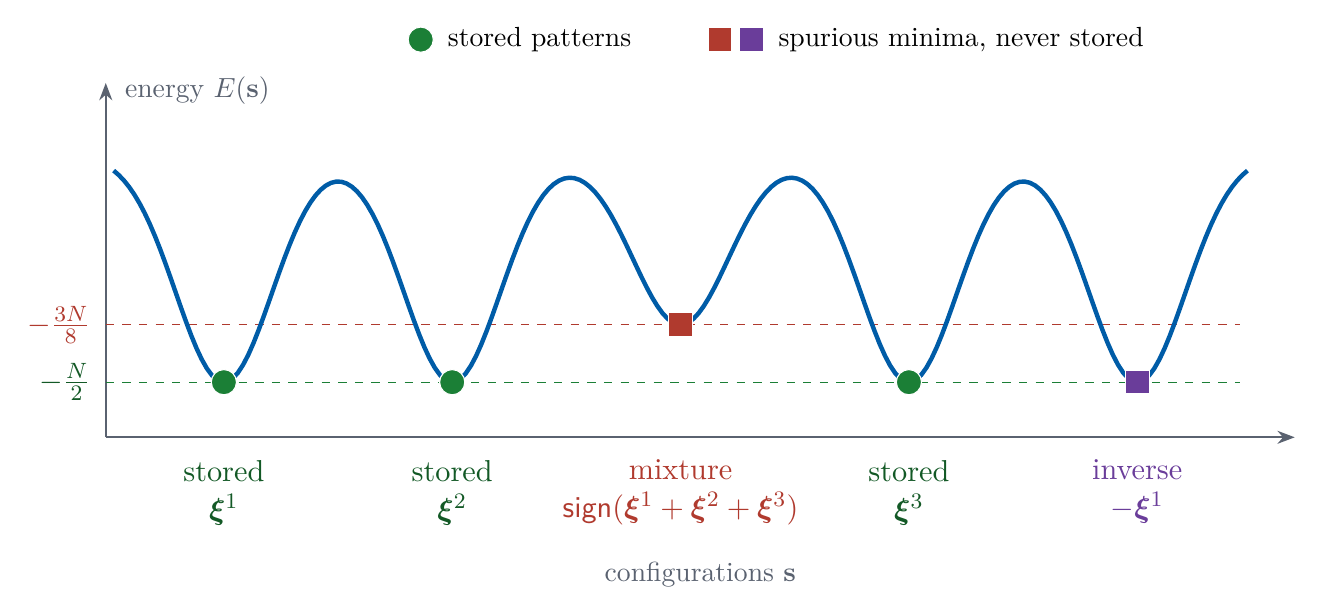

The sketch places both kinds in the energy landscape. The mixture state lies at the energy $-3N/8$, above the stored patterns, and the inverted pattern at the energy $-N/2$ of the patterns.

We first check both kinds for $p=3$ random patterns of $N=1000$ spins. A cue that agrees with the first pattern on 40 per cent of the spins should relax to the inverted pattern, and the mixture state (13) should be a fixed point with overlaps close to $\tfrac12$. We then search for minima without using this knowledge. For 40 sets of three random patterns of $N=500$ spins we relax ten random configurations each and classify every fixed point by its overlaps. One overlap above $0.9$ in magnitude marks a stored or an inverted pattern, three overlaps above $0.35$ in magnitude mark a mixture state of three patterns, and all other fixed points are counted separately. The figure shows the fraction of random starts that end in each class and the energies of the fixed points.

The next cell carries out the first check. The array `xi.sum(axis=0)` adds the three patterns at every spin and has shape `(N,)`, and `np.sign` turns it into the majority vote of equation (13).

In [27]:
N_SP = 1000
xi = random_patterns(3, N_SP, rng)                           # three random patterns, shape (3, N)
J = hebb(xi)
cue = flip_fraction(xi[0], 0.6, rng)                         # 60 per cent flipped, so the cue is closer to the inverted pattern
s_end = relax(J, cue, rng)
print(f"cue with overlap {cue @ xi[0] / N_SP:+.2f} with pattern 1: final overlaps {np.round(overlaps(xi, s_end), 3)}")

mixture = np.sign(xi.sum(axis=0))                            # majority vote, equation (13)
mix_fixed = bool(np.all(mixture * (J @ mixture) > 0))        # every spin of the mixture state is aligned with its field
m_mix = overlaps(xi, mixture)
mix_energy = float(energy(J, mixture) / N_SP)
print(f"mixture of the three patterns: overlaps {np.round(m_mix, 3)}, fixed point: {mix_fixed},"
      f" E/N = {mix_energy:.3f} (-3/8 = {-3 / 8}); stored pattern: E/N = {energy(J, xi[0]) / N_SP:.3f}")

cue with overlap -0.20 with pattern 1: final overlaps [-1.     0.03   0.082]
mixture of the three patterns: overlaps [0.452 0.518 0.466], fixed point: True, E/N = -0.343 (-3/8 = -0.375); stored pattern: E/N = -0.502


To search for minima, the next cell relaxes ten random configurations for each of 40 sets of patterns and sorts each fixed point into one of four classes by its overlaps `m`, of shape `(3,)`. The dictionary `found` collects the energies per spin of the fixed points of each class.

stored pattern   : 132 of 400 random starts (0.33 +- 0.02), E/N = -0.499, example overlaps [0.09 1.   0.04]
inverted pattern : 152 of 400 random starts (0.38 +- 0.02), E/N = -0.499, example overlaps [-0.06 -0.04 -1.  ]
mixture of three : 116 of 400 random starts (0.29 +- 0.02), E/N = -0.373, example overlaps [ 0.54  0.56 -0.41]
other            :   0 of 400 random starts (0.00 +- 0.00)
stored minus inverted: -20 starts, 1.2 standard errors


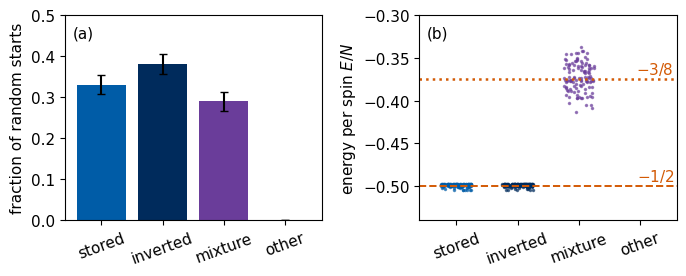

In [28]:
N_SEARCH, SETS_SEARCH, STARTS = 500, 40, 10
CLASSES = ("stored pattern", "inverted pattern", "mixture of three", "other")

def classify(m):
    if np.abs(m).max() > 0.9:                                # one overlap close to +1 or -1
        return "stored pattern" if m[np.argmax(np.abs(m))] > 0 else "inverted pattern"
    if np.abs(m).min() > 0.35:                               # all three overlaps sizeable
        return "mixture of three"
    return "other"

found = {c: [] for c in CLASSES}                             # energies per spin of the fixed points of each class
examples = {}                                                # the first overlaps seen in each class
for _ in range(SETS_SEARCH):
    xi = random_patterns(3, N_SEARCH, rng)
    J = hebb(xi)
    for _ in range(STARTS):
        start = random_patterns(1, N_SEARCH, rng)[0]         # one random configuration, shape (N,)
        s_end = relax(J, start, rng)
        m = overlaps(xi, s_end)
        c = classify(m)
        found[c].append(energy(J, s_end) / N_SEARCH)
        examples.setdefault(c, m)                            # stored only for the first fixed point of the class

total = SETS_SEARCH * STARTS
fractions = {c: len(found[c]) / total for c in CLASSES}
frac_err = {c: math.sqrt(fractions[c] * (1 - fractions[c]) / total) for c in CLASSES}    # binomial standard error
for c in CLASSES:
    e = np.array(found[c])
    print(f"{c:17s}: {len(e):3d} of {total} random starts ({fractions[c]:.2f} +- {frac_err[c]:.2f})"
          + (f", E/N = {e.mean():.3f}, example overlaps {np.round(examples[c], 2)}" if len(e) else ""))
# stored and inverted patterns are equally likely by symmetry; size of their difference in units of its standard error
n_stored, n_inverted = len(found["stored pattern"]), len(found["inverted pattern"])
print(f"stored minus inverted: {n_stored - n_inverted} starts, {abs(n_stored - n_inverted) / math.sqrt(n_stored + n_inverted):.1f} standard errors")
plot_spurious(CLASSES, fractions, frac_err, found)

In [29]:
time_core = time.perf_counter() - started
print(f"energy recomputed after every flip in {CHECKED['runs']} runs with {CHECKED['flips']} flips")

energy recomputed after every flip in 13 runs with 1741 flips


The cue with the overlap $-0.2$ relaxes to the inverted pattern. The mixture state (13) is a fixed point with overlaps between $0.45$ and $0.52$ and an energy per spin of $-0.34$ for this one set of patterns, whereas the estimate for large $N$ is $-3/8=-0.375$. The difference comes from the deviations of the three overlaps from $\tfrac12$, which are of order $1/\sqrt N$. Panel (a) shows where the 400 random starts end. About 33 per cent reach a stored pattern, 38 per cent an inverted pattern and 29 per cent a mixture state of three patterns, and no start ends elsewhere. Stored and inverted patterns are equally likely by the symmetry of the energy, and their measured difference of 20 starts is 1.2 standard errors. The mixture states found by the search include those in which one or more patterns enter with a minus sign. Panel (b) shows the energy per spin of every fixed point. Stored and inverted patterns have a mean of $-0.499$ and the mixture states a mean of $-0.373$, close to the values $-1/2$ and $-3/8$ of equation (12), which the two horizontal lines mark. With three stored patterns 67 per cent of the random initial configurations thus end in a state that was never stored, counting the inverted patterns.

So far the couplings were fixed and the spins moved downhill in energy. To read the Hebbian rule as learning, we now hold the spins at a pattern and regard the energy as a function of the couplings. The derivative of the energy (1) with respect to the coupling of the pair $(i,j)$ is $-s_is_j$. Adding the term $\xi_i^\mu\xi_j^\mu/N$ of equation (7) is therefore one step of gradient descent on the energy of the pattern $\boldsymbol\xi^\mu$, with the step size $1/N$. The Hebbian rule thus lowers the energy of the data and has no term aimed at configurations away from the data [6]. Minima that appear as a side effect, such as the mixture states and the blended digit of Section 7, are never removed. The Boltzmann machine adds such a term, which raises the energy of configurations that the model favours without support from the data [10]. Lab 079 builds this model and trains it on data.

### Summary of the core route

A Hopfield network is a set of spins with symmetric couplings, a zero diagonal and the energy (1). Aligning one spin at a time with its local field $\phi_i$ lowered the energy at each of the 1741 flips of the 13 runs in which we recomputed it, so the dynamics stops in a local minimum. The Hebbian rule builds the couplings from the patterns in one step. For random patterns the field at a stored pattern is a signal close to one plus a cross-talk of variance $p/N$, and our histogram and the fraction of misaligned spins reproduce the Gaussian estimate. In terms of the overlaps the energy is $-\tfrac N2\sum_\mu m_\mu^2+\tfrac p2$, so each pattern is a valley.

Two stored digit images were restored from a masked and from a noisy cue in single runs, and 39 of the 45 pairs of digits passed the same test. Three stored digits merged into their pixelwise majority, because each digit's overlaps with the other two add up to more than one, so that a pixel on which it stands alone is outvoted. For random patterns the capacity is the critical load $\alpha_c\approx0.138$ of Ref. [2]. Our recall rate falls around this load, more steeply for larger networks, and our sizes do not determine the threshold. Started at a stored pattern above the limit, the dynamics turns a small number of misaligned spins into a cascade of flips that ends at a partial overlap. The landscape also contains minima that were never stored, and with three random patterns about 33 per cent of the random starts ended in a stored pattern, 38 per cent in an inverted pattern and 29 per cent in a mixture state. These minima remain because the Hebbian rule only lowers the energy of the data.

The core route ends here.

## 10. Dense associative memory (at home)

This section is work at home and takes about one minute, nearly all of it in the comparison of the two energies.

### 10.1 A quartic energy

To raise the capacity by making the energy rise more steeply around each pattern, Ref. [7] replaces the square of the overlap in equation (12) by a higher power,
$$E_n(\mathbf s)=-\frac Nn\sum_{\mu=1}^{p}m_\mu^{\,n} , \tag{14}$$
which for $n=2$ is the energy (12) up to the constant $p/2$. A network with $n>2$ is called a dense associative memory. Its energy is no longer a sum over pairs of spins, since the power $m_\mu^n$ couples groups of $n$ spins. A coupling matrix $J_{ij}$ can no longer hold the memory, so the code below keeps the whole table of $p$ patterns and evaluates the overlaps from it. The larger capacity therefore requires this storage and the reading of all patterns at every update. With all other spins fixed, spin $i$ again takes the value that gives the lower energy, $s_i\leftarrow\mathrm{sign}\big[E_n(s_i=-1)-E_n(s_i=+1)\big]$, which for $n=2$ is the rule (3), and a spin for which both values give the same energy keeps its value. A flip is made only if it lowers the energy, so the dynamics stops after a finite number of flips.

By the argument of Section 5, the flip of one spin at a stored pattern $\boldsymbol\xi^\nu$ changes the overlap $m_\nu=1$ by $2/N$ and raises the energy (14) by about $2$ for every $n$, which is the signal. Each other pattern has an overlap of order $N^{-1/2}$ and changes the energy by $2m_\mu^{n-1}$ with a random sign, a term of order $N^{-(n-1)/2}$. The sum of $p$ such terms is of order $\sqrt p\,N^{-(n-1)/2}$ and stays below the signal as long as $p$ is small compared with $N^{n-1}$. The number of random patterns that can be stored therefore scales as $N^{n-1}$, compared with $N$ for $n=2$ [7].

We compare $n=2$ and $n=4$ for $N=40$ spins. For each number of patterns $p$ we draw 20 sets of random patterns and present five cues per set, each a stored pattern with 4 of its 40 spins flipped. The success criterion is that of Section 8, a final overlap above $0.9$, which for 40 spins allows one wrong spin. The error bars are standard errors of the 20 set averages. A single run with $n=4$, 400 stored patterns and a cue with 8 flipped spins first records the energy at every flip. The figure shows the recall rate against the number of stored patterns for both energies.

The next cell defines the energy and the dynamics. The array `sums` holds $Nm_\mu=\sum_i\xi_i^\mu s_i$ and has shape `(p,)`. To decide about all spins at once, the code forms `rest`, the array of shape `(p, N)` with $Nm_\mu-\xi_i^\mu s_i$, which is the sum for pattern $\mu$ without the contribution of spin $i$. The expression `sums[:, None]` adds an axis, shape `(p, 1)`, and `s[None, :]` has shape `(1, N)`, so NumPy repeats them along the missing axes, which is called broadcasting.

In [30]:
t_dense = time.perf_counter()

In [31]:
def dense_energy(xi, s, n):
    return -xi.shape[1] / n * np.sum((xi @ s / xi.shape[1]) ** n)   # equation (14), with m_mu = xi @ s / N

def dense_relax(xi, s, n, rng, record=False):
    # Asynchronous dynamics of the energy (14): a spin flips if the flip lowers the energy.
    s = s.copy()
    sums = xi @ s                                            # N m_mu for every pattern, shape (p,)
    E = [dense_energy(xi, s, n)]
    while True:
        # sums[:, None] has shape (p, 1), s[None, :] has shape (1, N); broadcasting gives shape (p, N)
        rest = sums[:, None] - xi * s[None, :]               # N m_mu without the contribution of spin i
        # (rest + xi)^n and (rest - xi)^n are the two values of (N m_mu)^n for s_i = +1 and s_i = -1
        gain = np.sum((rest + xi) ** n - (rest - xi) ** n, axis=0)   # E(s_i = -1) - E(s_i = +1) = gain / (n N^(n-1)), shape (N,)
        # gain > 0 means that s_i = +1 has the lower energy (14), so s_i * gain < 0 marks a spin whose flip lowers the energy
        misaligned = np.flatnonzero(s * gain < 0)
        if misaligned.size == 0:
            break
        for i in rng.permutation(misaligned):
            rest_i = sums - xi[:, i] * s[i]                  # xi[:, i] is column i, the values of spin i in all patterns
            if s[i] * np.sum((rest_i + xi[:, i]) ** n - (rest_i - xi[:, i]) ** n) < 0:   # the same test as `gain`, with current sums
                s[i] = -s[i]
                sums += 2 * s[i] * xi[:, i]                  # each N m_mu changes by 2 xi_i^mu s_i
                if record:
                    E.append(dense_energy(xi, s, n))
    return (s, np.array(E)) if record else s

N_D, SETS_D, CUES_D = 40, 20, 5
P_GRID = {2: (2, 4, 6, 8, 10, 12, 14, 16, 20, 24), 4: (100, 200, 300, 400, 500, 600, 700, 800, 1000, 1200, 1600)}

# energy check for the quartic energy on one run
xi = random_patterns(400, N_D, rng)
cue = flip_fraction(xi[0], 0.2, rng)
s_end, E_single = dense_relax(xi, cue, 4, rng, record=True)
assert np.all(np.diff(E_single) < 0)
print(f"n = 4, p = 400, N = {N_D}: single run with {len(E_single) - 1} flips, every flip lowered the energy, final overlap {s_end @ xi[0] / N_D:.2f}")

n = 4, p = 400, N = 40: single run with 8 flips, every flip lowered the energy, final overlap 1.00


The next cell measures the recall rate for both energies. The dictionary `dense` receives, for each $n$, the numbers of patterns, the recall rates and their standard errors. The function `half_point` then finds the number of patterns at which the rate crosses one half, by linear interpolation in $\ln p$ between the two neighbouring measured points.

n = 2: p = 2: 1.00, p = 4: 0.96, p = 6: 0.89, p = 8: 0.67, p = 10: 0.56, p = 12: 0.27, p = 14: 0.23, p = 16: 0.11, p = 20: 0.03, p = 24: 0.00
n = 4: p = 100: 1.00, p = 200: 1.00, p = 300: 0.94, p = 400: 0.91, p = 500: 0.80, p = 600: 0.65, p = 700: 0.53, p = 800: 0.44, p = 1000: 0.23, p = 1200: 0.14, p = 1600: 0.06
recall rate one half at p = 10.4 (n = 2) and p = 732 (n = 4)


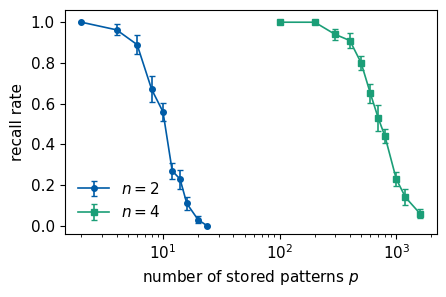

In [32]:
dense = {}
for n, grid in P_GRID.items():
    rate = np.zeros((len(grid), SETS_D))                     # rows are numbers of patterns, columns are sets
    for p_index, p in enumerate(grid):
        for k in range(SETS_D):
            xi = random_patterns(p, N_D, rng)
            cues = min(CUES_D, p)                            # for p = 2 and p = 4 every stored pattern is cued once
            successes = []
            for mu in range(cues):
                cue = flip_fraction(xi[mu], 0.1, rng)
                successes.append(xi[mu] @ dense_relax(xi, cue, n, rng) / N_D > M_SUCCESS)
            rate[p_index, k] = np.mean(successes)
    dense[n] = dict(p=list(grid), rate=rate.mean(1), err=rate.std(1, ddof=1) / np.sqrt(SETS_D))
    print(f"n = {n}: " + ", ".join(f"p = {p}: {r:.2f}" for p, r in zip(grid, dense[n]["rate"])))

def half_point(n):
    log_p, r = np.log(dense[n]["p"]), dense[n]["rate"]
    k = int(np.argmax(r < 0.5))                              # first index at which the rate is below one half
    # straight line through (ln p_(k-1), r_(k-1)) and (ln p_k, r_k), solved for the rate 1/2 and turned back into p
    return float(np.exp(log_p[k - 1] + (r[k - 1] - 0.5) / (r[k - 1] - r[k]) * (log_p[k] - log_p[k - 1])))

half = {n: half_point(n) for n in P_GRID}
print(f"recall rate one half at p = {half[2]:.1f} (n = 2) and p = {half[4]:.0f} (n = 4)")
plot_dense(dense)

In [33]:
time_dense = time.perf_counter() - t_dense

The figure shows the recall rate against the number of stored patterns on a logarithmic axis, for the quadratic energy (blue circles) and the quartic energy (teal squares). In the single run with $n=4$ and 400 stored patterns each of the 8 flips lowers the energy. With the quadratic energy the recall rate of the 40 spins falls to one half at about 10 patterns, and with the quartic energy at about 730 patterns, a factor of about 70 more in the same 40 spins. For $n=2$ the interpolated half point, printed as $p=10.4$, corresponds to the load $0.26$, well above $0.138$, which continues the trend of Section 8 that small networks lose their recall more gradually. This experiment uses one small size and does not test the scaling $N^{n-1}$.

### 10.2 One update with Boltzmann weights

With an exponential in place of the power, $E=-\sum_\mu\exp(\boldsymbol\xi^\mu\cdot\mathbf s)$, the number of patterns that can be stored grows exponentially with $N$ [8], and Ref. [9] extended this energy to continuous states. One update of the network of Ref. [9] replaces the state $\mathbf s$ by
$$\mathbf s'=\sum_{\mu=1}^{p}w_\mu\,\boldsymbol\xi^\mu,\qquad w_\mu=\frac{\exp\big(\beta\,\boldsymbol\xi^\mu\cdot\mathbf s\big)}{\sum_{\mu'=1}^{p}\exp\big(\beta\,\boldsymbol\xi^{\mu'}\cdot\mathbf s\big)} . \tag{15}$$
The weights $w_\mu$ are Boltzmann weights of the stored patterns, with the energies $-\boldsymbol\xi^\mu\cdot\mathbf s=-Nm_\mu$ and the inverse temperature $\beta$, and the new state is the average of the stored patterns with these weights. When $\beta N$ times the difference between the two largest overlaps is large, the pattern closest to the cue carries almost all the weight and a single update returns it. One update is therefore a soft search for the nearest stored pattern, and like the quartic network it needs the full table of patterns.

The same formula occurs in the attention layer of a transformer, a neural network for sequences. That layer compares a query vector with a set of stored key vectors through scalar products, turns the results into weights with the same exponential form, and returns the weighted average of stored value vectors. Equation (15) is this operation with the cue as the query and the patterns as both keys and values [9].

We apply one update (15) with $\beta=0.3$ to a memory that holds all ten digit images, of which the Hebbian network of Section 7 keeps none as a fixed point, and take the sign of the result. The cues are the ten digits with the lower half masked and the ten digits with 25 per cent of the pixels flipped. This is a different model from the network of Sections 2 to 9, and each of the 20 recalls is a single run. The figure shows the masked cues in the upper row and the outputs in the lower row.

The function `boltzmann_update` takes the table `xi` of shape `(p, N)`, a cue of shape `(N,)` and $\beta$, and returns the output of shape `(N,)` together with the weights of shape `(p,)`. Subtracting the largest exponent before taking the exponential avoids numbers too large for the computer and leaves the weights unchanged, because the normalisation removes the common factor.

In [34]:
BETA = 0.3

def boltzmann_update(xi, s, beta):
    score = beta * (xi @ s)                                  # beta xi^mu . s for every pattern, shape (p,)
    w = np.exp(score - score.max())                          # unnormalised weights, the largest equals 1
    w /= w.sum()                                             # the weights w_mu of equation (15)
    # w @ xi is the weighted average of the rows of xi, shape (N,); np.sign turns it into a spin configuration
    return np.sign(w @ xi), w

The next cell applies the update to the 20 cues. For each cue it stores the number of wrong pixels, the weight of the correct digit, the digit with the largest weight, the stored digit closest to the cue, and the stored digit that the output equals, if any.

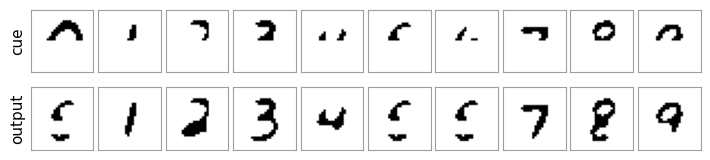

In [35]:
boltzmann_runs = []
masked_cues, masked_outputs = [], []
for d in range(10):
    masked = xi_digits[d].copy()
    masked[N_IMG // 2:] = 1.0
    noisy = flip_fraction(xi_digits[d], 0.25, rng)
    for kind, cue in (("masked", masked), ("noisy", noisy)):
        out, w = boltzmann_update(xi_digits, cue, BETA)
        m_cue = overlaps(xi_digits, cue)                     # overlap of the cue with each stored digit, shape (10,)
        boltzmann_runs.append(dict(digit=d, cue=kind, weight_of_digit=float(w[d]), largest_weight_at=int(np.argmax(w)), largest_weight=float(w.max()),
                                   wrong_pixels=int(np.sum(out != xi_digits[d])), closest_digit=int(np.argmax(m_cue)),
                                   overlap_with_own_digit=float(m_cue[d]), overlap_with_largest=float(m_cue[np.argmax(w)]),
                                   output_equals_digit=[k for k in range(10) if np.array_equal(out, xi_digits[k])]))
        if kind == "masked":
            masked_cues.append(cue); masked_outputs.append(out)
plot_boltzmann(masked_cues, masked_outputs)

In [36]:
for kind in ("masked", "noisy"):
    runs = [run for run in boltzmann_runs if run["cue"] == kind]
    print(f"{kind} cues: {sum(run['wrong_pixels'] == 0 for run in runs)} of 10 digits returned without a wrong pixel;"
          f" weight of the correct digit: " + " ".join(f"{run['weight_of_digit']:.2f}" for run in runs))
    for run in runs:
        if run["wrong_pixels"]:
            print(f"   {kind} cue of the digit {run['digit']}: {run['wrong_pixels']} wrong pixels, largest weight {run['largest_weight']:.2f} on the digit {run['largest_weight_at']},"
                  f" overlaps of the cue with the digits {run['digit']} and {run['largest_weight_at']}:"
                  f" {run['overlap_with_own_digit']:.3f} and {run['overlap_with_largest']:.3f}, output equals the stored digit {run['output_equals_digit']}")
closest_returned = sum(run["output_equals_digit"] == [run["closest_digit"]] for run in boltzmann_runs)
print(f"runs in which the output equals the stored digit closest to the cue: {closest_returned} of {len(boltzmann_runs)}")

masked cues: 8 of 10 digits returned without a wrong pixel; weight of the correct digit: 0.35 1.00 0.87 1.00 1.00 1.00 0.00 1.00 1.00 1.00
   masked cue of the digit 0: 107 wrong pixels, largest weight 0.64 on the digit 5, overlaps of the cue with the digits 0 and 5: 0.819 and 0.821, output equals the stored digit [5]
   masked cue of the digit 6: 99 wrong pixels, largest weight 1.00 on the digit 5, overlaps of the cue with the digits 6 and 5: 0.821 and 0.890, output equals the stored digit [5]
noisy cues: 10 of 10 digits returned without a wrong pixel; weight of the correct digit: 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00
runs in which the output equals the stored digit closest to the cue: 20 of 20


In [37]:
time_home = time.perf_counter() - t_dense

One update returns 8 of the ten digits from the masked cues and all ten from the noisy cues without a wrong pixel, although the ten images are strongly correlated. In the two failures, the masked 0 and the masked 6, the cue has a larger overlap with the stored digit 5 than with its own digit, the digit 5 carries the largest weight, and the output is the digit 5 without a wrong pixel. The output equals the stored pattern with the largest overlap with the cue in all 20 runs, which is what a search for the nearest stored pattern returns, and a cue that lacks too much of a digit is closer to a different one.

## 11. Summary of the dense memory

The capacity of the Hopfield network with the quadratic energy is proportional to $N$, with the limit $0.138N$ of Ref. [2], and it grows when the energy is made steeper. A quartic energy raised the number of patterns at which 40 spins recall half of the cues from about 10 to about 730, at the price of keeping all patterns in memory. One update with Boltzmann weights over the stored patterns returned 8 of the ten correlated digit images from masked cues and all ten from noisy cues, and in all 20 runs its output was the stored digit closest to the cue.

## 12. Exercises

Each exercise has a code cell. Write your computation there, replace `None` by your result and run the cell, and the check function reports whether the result agrees. The check functions are in the next, collapsed cell. Exercises 1 to 3 need only the core route, and Exercise 4 needs Section 10. Use your own random generators as stated, so that the generator `rng` of the notebook is not advanced.

In [38]:
def check_exercise_1(raising_flip, oscillation, higher_with_diagonal):
    if raising_flip is None:
        print("Part (a), no answer yet. Expected a tuple (J, s, k).")
    else:
        J_a, s_a, k = raising_flip
        flipped = s_a.copy(); flipped[k] *= -1
        rule_flips = s_a[k] * (J_a @ s_a)[k] < 0
        print("Part (a) is correct." if rule_flips and energy(J_a, flipped) > energy(J_a, s_a) else
              "Part (a) differs. Spin k must point against its field, and the energy (1) must rise when it flips.")
    if oscillation is None:
        print("Part (b), no answer yet. Expected a list of five tuples.")
    else:
        expected = [(1, 1), (-1, -1), (1, 1), (-1, -1), (1, 1)]
        print("Part (b) is correct." if [tuple(int(v) for v in s) for s in oscillation] == expected else
              "Part (b) differs. Compute both new values from the old configuration before replacing it.")
    if higher_with_diagonal is None:
        print("Part (c), no answer yet. Expected a number from 0 to 10.")
    else:
        xi_c = random_patterns(40, 200, np.random.default_rng(0))
        J_zero, J_diag = hebb(xi_c), xi_c.T @ xi_c / 200
        count = 0
        for seed in range(10):
            start = random_patterns(1, 200, np.random.default_rng(seed))[0]
            end_zero = relax(J_zero, start, np.random.default_rng(seed))
            end_diag = relax(J_diag, start, np.random.default_rng(seed))
            count += energy(J_zero, end_diag) > energy(J_zero, end_zero)
        print(f"Part (c) is correct, {count} of 10 runs." if higher_with_diagonal == count else
              "Part (c) differs. Evaluate both final energies with the zero-diagonal couplings.")

def check_exercise_2(rates):
    if rates is None:
        print("Exercise 2, no answer yet. Expected a dictionary {(load, fraction): rate}.")
        return
    keys = [(a, f) for a in (0.05, 0.10) for f in (0.1, 0.2, 0.3, 0.4, 0.5)]
    if any(k not in rates for k in keys):
        print("Exercise 2 needs all ten combinations of the loads 0.05, 0.10 and the fractions 0.1 to 0.5.")
    elif min(rates[a, 0.1] for a in (0.05, 0.10)) >= 0.9 and max(rates[a, 0.5] for a in (0.05, 0.10)) <= 0.3:
        print("Exercise 2 passes the check. The rate is high for small damage and low for a cue without overlap.")
    else:
        print("Exercise 2 differs. A cue with 10 per cent of flipped spins should be recalled, one with 50 per cent should not.")

def check_exercise_3(m_five, five_is_fixed):
    if m_five is None or five_is_fixed is None:
        print("Exercise 3, no answer yet.")
        return
    xi_5 = random_patterns(5, 1000, np.random.default_rng(5))
    J_5, mix_5 = hebb(xi_5), np.sign(xi_5.sum(axis=0))
    good = np.allclose(m_five, overlaps(xi_5, mix_5)) and bool(five_is_fixed) == bool(np.all(mix_5 * (J_5 @ mix_5) > 0))
    print(f"Exercise 3 is correct. Mean overlap {np.mean(m_five):.3f}, compared with 3/8." if good else
          "Exercise 3 differs. Use random_patterns(5, 1000, np.random.default_rng(5)).")

def check_exercise_4(restored_counts):
    if "boltzmann_update" not in globals():
        print("Exercise 4 needs Section 10.")
    elif restored_counts is None:
        print("Exercise 4, no answer yet. Expected a dictionary {beta: count}.")
    else:
        reference = {}
        for beta in (0.001, 0.01, 0.1, 0.3, 1.0):
            reference[beta] = 0
            for d in range(10):
                masked = xi_digits[d].copy(); masked[N_IMG // 2:] = 1.0
                reference[beta] += int(np.array_equal(boltzmann_update(xi_digits, masked, beta)[0], xi_digits[d]))
        print(f"Exercise 4 is correct: {reference}" if restored_counts == reference else
              "Exercise 4 differs. Count a digit only if the output has no wrong pixel.")

### Exercise 1. Assumptions of the descent proof

The proof of Section 2 uses symmetric couplings, updates of one spin at a time and a zero diagonal.

(a) Draw couplings without symmetrising them and find a flip made by the rule (3) that raises the energy (1). It helps to repeat the derivation of equation (4) for $J_{kj}\neq J_{jk}$ and to compare $\Delta E$ with $2s_k\phi_k$. Store the result as `raising_flip = (J, s, k)`.

(b) Take two spins with $J_{12}=J_{21}=-1$, start from $\mathbf s=(+1,+1)$ and update both spins simultaneously, four times. Store the five configurations in the list `oscillation`.

(c) A diagonal coupling $J_{kk}$ adds the constant $-\tfrac12J_{kk}$ to the energy, since $s_k^2=1$, and it adds the term $J_{kk}s_k$ to the field (2). The rule (3) would then flip a spin only if $s_k\sum_{j\neq k}J_{kj}s_j<-J_{kk}$. For a positive $J_{kk}$ the energy still decreases at every flip, but a spin whose flip would lower the energy by less than $2J_{kk}$ stays, and the dynamics can stop at a configuration that is no local minimum. With $J_{kk}=0$ the fixed points of the rule (3) and the configurations that no single flip improves coincide. Take `xi = random_patterns(40, 200, np.random.default_rng(0))`, the couplings `hebb(xi)` and the same couplings with diagonal, `xi.T @ xi / 200`. For each seed from 0 to 9 draw `random_patterns(1, 200, np.random.default_rng(seed))[0]`, relax it with both couplings, each with a new `np.random.default_rng(seed)`, and evaluate both final configurations with the zero-diagonal couplings. Store in `higher_with_diagonal` how many of the ten runs end higher in energy with the diagonal.

In [39]:
raising_flip = None
oscillation = None
higher_with_diagonal = None

check_exercise_1(raising_flip, oscillation, higher_with_diagonal)

Part (a), no answer yet. Expected a tuple (J, s, k).
Part (b), no answer yet. Expected a list of five tuples.
Part (c), no answer yet. Expected a number from 0 to 10.


### Exercise 2. Size of the basin of attraction

For $N=1000$, the loads $0.05$ and $0.10$ and the fractions $0.1,0.2,0.3,0.4,0.5$ of flipped spins, measure the recall rate with the success criterion of Section 8. Use the generator `np.random.default_rng(2)`, two sets of patterns per point and five cues per set, following the body of `recall_at_load`. Store the rates in the dictionary `rates` with keys `(load, fraction)`, and plot the rate against the fraction.

In [40]:
rates = None

check_exercise_2(rates)

Exercise 2, no answer yet. Expected a dictionary {(load, fraction): rate}.


### Exercise 3. Mixture of five patterns

Draw `xi5 = random_patterns(5, 1000, np.random.default_rng(5))`, build the mixture state by the majority rule, compute its five overlaps `m_five` and test whether it is a fixed point, `five_is_fixed`. The spin $\xi_i^1$ differs from the majority if at least three of the four other patterns differ from it, which gives the overlap $3/8$.

In [41]:
m_five = None
five_is_fixed = None

check_exercise_3(m_five, five_is_fixed)

Exercise 3, no answer yet.


### Exercise 4. Inverse temperature of the update (needs Section 10)

Apply `boltzmann_update` to the ten masked digits for $\beta=0.001,0.01,0.1,0.3,1$, and count for each $\beta$ the digits returned without a wrong pixel. Store the counts in the dictionary `restored_counts`. Explain the output in the limit of small $\beta$, in which all weights $w_\mu$ become equal.

In [42]:
restored_counts = None

check_exercise_4(restored_counts)

Exercise 4, no answer yet. Expected a dictionary {beta: count}.


## References

[1] J. J. Hopfield, Neural networks and physical systems with emergent collective computational abilities, Proc. Natl. Acad. Sci. USA **79**, 2554 (1982), doi:[10.1073/pnas.](https://doi.org/10.1073/pnas.).

[2] D. J. Amit, H. Gutfreund and H. Sompolinsky, Storing infinite numbers of patterns in a spin-glass model of neural networks, Phys. Rev. Lett. **55**, 1530 (1985), doi:[10.1103/PhysRevLett.55.1530](https://doi.org/10.1103/PhysRevLett.55.1530).

[3] Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, Gradient-based learning applied to document recognition, Proc. IEEE **86**, 2278 (1998), doi:[10.1109/5.726791](https://doi.org/10.1109/5.726791).

[4] D. O. Hebb, The Organization of Behavior (Wiley, New York, 1949), reissued by Psychology Press (2005), doi:[10.4324/9781410612403](https://doi.org/10.4324/9781410612403).

[5] D. J. Amit, H. Gutfreund and H. Sompolinsky, Spin-glass models of neural networks, Phys. Rev. A **32**, 1007 (1985), doi:[10.1103/PhysRevA.32.1007](https://doi.org/10.1103/PhysRevA.32.1007).

[6] A. Dawid and Y. LeCun, Introduction to latent variable energy-based models: a path toward autonomous machine intelligence, J. Stat. Mech. (2024) 104011, doi:[10.1088/1742-5468/ad292b](https://doi.org/10.1088/1742-5468/ad292b).

[7] D. Krotov and J. J. Hopfield, Dense associative memory for pattern recognition, Advances in Neural Information Processing Systems 29 (2016), [arXiv:1606.01164](https://arxiv.org/abs/1606.01164).

[8] M. Demircigil, J. Heusel, M. Löwe, S. Upgang and F. Vermet, On a model of associative memory with huge storage capacity, J. Stat. Phys. **168**, 288 (2017), doi:[10.1007/s10955-017-1806-y](https://doi.org/10.1007/s10955-017-1806-y).

[9] H. Ramsauer, B. Schäfl, J. Lehner, P. Seidl, M. Widrich, T. Adler, L. Gruber, M. Holzleitner, M. Pavlović, G. K. Sandve, V. Greiff, D. Kreil, M. Kopp, G. Klambauer, J. Brandstetter and S. Hochreiter, Hopfield networks is all you need, [arXiv:2008.02217](https://arxiv.org/abs/2008.02217) (2020).

[10] D. H. Ackley, G. E. Hinton and T. J. Sejnowski, A learning algorithm for Boltzmann machines, Cogn. Sci. **9**, 147 (1985), doi:[10.1207/s15516709cog0901_7](https://doi.org/10.1207/s15516709cog0901_7).

In [43]:
home_done = "time_home" in globals()
time_total = time.perf_counter() - started
one_pattern = {f: dict(m_cue=float(m0), m_end=float(m1), wrong_spins_in_cue=int(np.sum(c != e)), flips=int(np.sum(c != e)))
               for f, (c, e, m0, m1) in zip((0.3, 0.6), one_pattern_runs)}
image_summary = {run["name"]: dict(flips=len(run["flips"]), m_cue=run["m_cue"].tolist(), m_end=run["m_end"].tolist(),
                                   wrong_pixels=int(np.sum(run["s_end"] != run["stored"]))) for run in image_runs}
m_blend = overlaps(xi_triple, triple_end[0])
blend_check = []
for a in range(3):
    others = [b for b in range(3) if b != a]
    q_sum = q_triple[a, others].sum()
    minority = np.all(xi_triple[others] != xi_triple[a], axis=0)
    alignment = xi_triple[a] * (J_triple @ xi_triple[a])
    predicted = 1 - q_sum - 3 / N_IMG
    blend_check.append(dict(digit=TRIPLE[a], q_sum=float(q_sum), minority_pixels=int(minority.sum()), misaligned_pixels=int(np.sum(alignment < 0)),
                            same_pixels=bool(np.array_equal(minority, alignment < 0)), predicted_alignment=float(predicted),
                            measured_alignment_max_deviation=float(np.abs(alignment[minority] - predicted).max())))
rr = REPORT["recall_run"]
NUMBERS = dict(GlassN=f"{N_GLASS}", GlassFlipsMin=f"{min(len(E) - 1 for E in glass_runs)}", GlassFlipsMax=f"{max(len(E) - 1 for E in glass_runs)}",
               GlassEMin=f"{glass_final.min():.2f}", GlassEMax=f"{glass_final.max():.2f}",
               ImageN=f"{N_IMG}", OneFlipsNear=f"{one_pattern[0.3]['flips']}", OneFlipsFar=f"{one_pattern[0.6]['flips']}",
               RandomOverlapMax=f"{random_overlap_max:.2f}",
               CrosstalkN=f"{N_CT}", CrosstalkVarPointTwo=f"{crosstalk[0.2]['variance']:.3f}",
               FlipFracLowest=f"{100 * crosstalk[0.08]['fraction']:.3f}", FlipDevMax=f"{max(abs(d) for d in dev.values()):.1f}",
               FlipDevFiniteMax=f"{max(abs(d) for d in dev_finite.values()):.1f}", FlipBelow=f"{sum(d < 0 for d in dev.values())}",
               FlipFracCapacity=f"{100 * crosstalk[0.138]['fraction']:.2f}", FlipGaussCapacity=f"{100 * tail(0.138):.2f}",
               FlipFracHalf=f"{100 * crosstalk[0.5]['fraction']:.1f}", FlipGaussHalf=f"{100 * tail(0.5):.1f}",
               OverlapN=f"{N_OV}", OverlapP=f"{P_OV}", RecallFlips=f"{rr['flips']}",
               RecallOtherMax=f"{math.ceil(100 * rr['other_max_run']) / 100:.2f}", RecallECue=f"{rr['E_cue']:.0f}", RecallEEnd=f"{rr['E_end']:.0f}",
               PairOverlap=f"{q_pair:.2f}", PairsOk=f"{pairs_restored}", PairsAll=f"{pairs_tested}",
               PairFailuresMasked=f"{sum(f['cue'] == 'masked' for f in pair_failures)}", PairFailuresNoisy=f"{sum(f['cue'] == 'noisy' for f in pair_failures)}",
               PairFailuresCloser=f"{sum(np.argmax(f['cue_overlaps']) == np.argmax(f['final_overlaps']) and f['pair'][int(np.argmax(f['cue_overlaps']))] != f['cued_digit'] for f in pair_failures)}",
               PairsFailed=f"{pairs_tested - pairs_restored}", MaskedFlips=f"{image_summary['masked']['flips']}", NoisyFlips=f"{image_summary['noisy']['flips']}",
               DigitOverlapMin=f"{q_off.min():.2f}", DigitOverlapMax=f"{q_off.max():.2f}", BlendOverlapA=f"{m_blend[0]:.2f}",
               BlendOverlapB=f"{m_blend[1]:.2f}", BlendOverlapC=f"{m_blend[2]:.2f}",
               BlendSumMin=f"{min(c['q_sum'] for c in blend_check):.2f}", BlendSumMax=f"{max(c['q_sum'] for c in blend_check):.2f}",
               BlendTriples=f"{triples_blended}", BlendTripleSumMin=f"{q_sum_min:.2f}", BlendStartsToMajority=f"{starts_reaching_majority}", TenDigitsStable=f"{ten_stable}",
               MaskedRestoredBackground=f"{restored_background}", MaskedRestoredUndecided=f"{restored_undecided}",
               CapSets=f"{SETS}", CapCues=f"{CUES}", CapTrials=f"{SETS * CUES}", RuntimeCapacity=f"{time_capacity:.0f}")
def rate_at(N, alpha):
    return capacity[N]["rate"][int(np.argmin(np.abs(LOADS - alpha)))]
for N, size_name in zip(SIZES, ("Small", "Mid", "Large")):
    for alpha, load_name in ((0.10, "PointTen"), (0.14, "PointFourteen"), (0.18, "PointEighteen")):
        NUMBERS[f"CapRate{size_name}{load_name}"] = f"{rate_at(N, alpha):.2f}"
    NUMBERS[f"CapOverlap{size_name}Top"] = f"{capacity[N]['m'][-1]:.2f}"
NUMBERS.update(CapOverlapLargeLow=f"{capacity[1000]['m'][int(np.argmin(np.abs(LOADS - 0.10)))]:.3f}", CapOverlapLargeHigh=f"{capacity[1000]['m'][-1]:.2f}",
               CapRateLargeTop=f"{capacity[1000]['rate'][-1]:.2f}",
               CascadeMisalignedLow=f"{cascade[0.10]['misaligned_at_start']:.1f}", CascadeFlipsLow=f"{cascade[0.10]['flips']:.1f}",
               CascadeMisalignedLimit=f"{cascade[0.138]['misaligned_at_start']:.1f}", CascadeFlipsLimit=f"{cascade[0.138]['flips']:.0f}",
               CascadeMisalignedHigh=f"{cascade[0.20]['misaligned_at_start']:.1f}", CascadeFlipsHigh=f"{cascade[0.20]['flips']:.0f}",
               CascadeOverlapHigh=f"{cascade[0.20]['final_overlap']:.2f}",
               SearchN=f"{N_SEARCH}", SearchTotal=f"{total}", SearchPattern=f"{100 * fractions['stored pattern']:.0f}",
               SearchInverted=f"{100 * fractions['inverted pattern']:.0f}", SearchMixture=f"{100 * fractions['mixture of three']:.0f}",
               SearchOther=f"{len(found['other'])}", MixtureEnergy=f"{mix_energy:.2f}",
               MixtureOverlapMin=f"{m_mix.min():.2f}", MixtureOverlapMax=f"{m_mix.max():.2f}",
               SearchSpurious=f"{100 * (fractions['inverted pattern'] + fractions['mixture of three']):.0f}",
               SearchPatternEnergy=f"{np.mean(found['stored pattern'] + found['inverted pattern']):.3f}", SearchMixtureEnergy=f"{np.mean(found['mixture of three']):.3f}",
               EnergyCheckRuns=f"{CHECKED['runs']}", EnergyCheckFlips=f"{CHECKED['flips']}", RuntimeCore=f"{time_core:.0f}")
summary = dict(
    experiment="Hopfield network with Hebbian couplings and asynchronous zero-temperature dynamics; NumPy float64 on CPU, seed 78",
    energy_check=dict(runs=CHECKED["runs"], flips=CHECKED["flips"], statement="energy recomputed from equation (1) after every flip; no flip raised it"),
    random_couplings=dict(N=N_GLASS, final_energy_per_spin=glass_final.tolist(), flips=[len(E) - 1 for E in glass_runs]),
    one_pattern={str(k): v for k, v in one_pattern.items()},
    crosstalk=dict(N=N_CT, sets=SETS_CT, zero_field_spins_count_one_half=True, loads={str(a): v for a, v in crosstalk.items()}),
    overlaps=dict(N=N_OV, p=P_OV, identity_largest_difference=identity_error, single_run=rr),
    images=dict(source="pixel-wise majority images of the ten digit classes of the MNIST training set, Ref. [3], file data/lab078_mnist_class_means.npz", pair=list(PAIR), pair_overlap=q_pair, single_runs=image_summary,
                pairs_restored=pairs_restored, pairs_tested=pairs_tested, pair_failures=pair_failures,
                masked_cues_restored=dict(background_start=restored_background, undecided_start=restored_undecided, total=90, seed=7803),
                triple=list(TRIPLE), triple_patterns_are_fixed_points=[int(np.all(x * (J_triple @ x) > 0)) for x in xi_triple],
                triple_common_fixed_point=all(np.array_equal(triple_end[0], s) for s in triple_end),
                triple_fixed_point_overlaps=m_blend.tolist(), digit_overlap_range=[float(q_off.min()), float(q_off.max())],
                blend_check=blend_check, fixed_point_is_majority=bool(np.array_equal(majority, triple_end[0])), triples_blended_of_120=triples_blended,
                starts_reaching_majority_of_360=int(starts_reaching_majority), smallest_overlap_sum_over_triples=q_sum_min, fixed_points_with_all_ten_stored=ten_stable),
    capacity=dict(loads=LOADS.tolist(), sets=SETS, cues_per_set=CUES, cue_noise=CUE_NOISE, success_overlap=M_SUCCESS, quoted_limit_ref2=ALPHA_C,
                  sizes={str(N): {k: v.tolist() for k, v in capacity[N].items()} for N in SIZES}),
    cascade=dict(N=N_CASCADE, sets=SETS_CASCADE, seed=7801, start="the first stored pattern, no noise", loads={str(a): v for a, v in cascade.items()}),
    spurious=dict(N=N_SEARCH, p=3, sets=SETS_SEARCH, starts_per_set=STARTS, fractions=fractions, fraction_errors=frac_err,
                  mean_energy_per_spin={c: (float(np.mean(found[c])) if found[c] else None) for c in CLASSES},
                  mixture_check=dict(N=N_SP, overlaps=m_mix.tolist(), fixed_point=mix_fixed)),
    runtime_seconds=dict(core_sections_1_9=time_core, capacity_section_8=time_capacity, total=time_total))
json_file, tex_file = RES / "lab078_results.json", FIG / "nb_numbers_lab078.tex"
if home_done:
    failed = [run for run in boltzmann_runs if run["wrong_pixels"]]
    NUMBERS.update(DenseSets=f"{SETS_D}", DenseN=f"{N_D}", DenseLoadHalfTwo=f"{half[2] / N_D:.2f}", RuntimeDense=f"{time_dense:.0f}",
                   DenseSingleFlips=f"{len(E_single) - 1}", DenseHalfTwo=f"{half[2]:.0f}", DenseHalfFour=f"{10 * round(half[4] / 10):.0f}", DenseTrials=f"{SETS_D * CUES_D}",
                   DenseRatio=f"{10 * round(half[4] / half[2] / 10):.0f}",
                   SoftmaxMaskedOk=f"{sum(r['wrong_pixels'] == 0 for r in boltzmann_runs if r['cue'] == 'masked')}",
                   SoftmaxNoisyOk=f"{sum(r['wrong_pixels'] == 0 for r in boltzmann_runs if r['cue'] == 'noisy')}", SoftmaxFailed=f"{len(failed)}",
                   SoftmaxClosest=f"{closest_returned}",
                   SoftmaxFailedOther=f"{sum(r['largest_weight_at'] != r['digit'] and r['output_equals_digit'] == [r['largest_weight_at']] for r in failed)}",
                   RuntimeHome=f"{time_home:.0f}")
    summary["at_home"] = dict(dense=dict(N=N_D, sets=SETS_D, cues_per_set=CUES_D, cue_noise=0.1,
                                         results={str(n): dict(p=v["p"], rate=v["rate"].tolist(), err=v["err"].tolist()) for n, v in dense.items()},
                                         half_recall_p={str(n): v for n, v in half.items()}),
                              boltzmann_update=dict(beta=BETA, runs=boltzmann_runs))
    summary["runtime_seconds"]["at_home_section_10"] = time_home
if EXPORT:
    import re
    if not home_done:
        for name, value in re.findall(r"\\newcommand\{\\labseventyeight(\w+)\}\{(.*)\}", tex_file.read_text()):
            NUMBERS.setdefault(name, value)
        summary["at_home"] = json.loads(json_file.read_text()).get("at_home")
    summary["numbers"] = dict(NUMBERS)
    json_file.write_text(json.dumps(summary, indent=2))
    with open(tex_file, "w") as f:
        for name, value in NUMBERS.items():
            f.write(f"\\newcommand{{\\labseventyeight{name}}}{{{value.strip()}}}\n")
print(f"run time: Sections 1 to 9 {time_core:.1f} s" + (f", Section 10 {time_home:.1f} s" if home_done else "") + f", total {time_total:.1f} s")

run time: Sections 1 to 9 37.9 s, Section 10 36.5 s, total 74.4 s
